# Astrophysics

Ein Spielplatz für den Einstieg in die Astrophysik: wichtige öffentliche Datenbanken anzapfen und die grundlegenden Plots des Fachs selbst machen. Sechs Teile, jeder mit echten Daten: Galaxien (SIMBAD, NED, NASA SkyView, SDSS, DESI Legacy Surveys), Nebel (Gaia, 2MASS, WISE, Planck, Pan-STARRS, VizieR, Palomar-Platten), Exoplaneten (Kepler über MAST, NASA Exoplanet Archive, Gaia, JWST), Gravitationswellen (LIGO über das Gravitational Wave Open Science Center), die Sonne (SILSO, GOES-Satelliten, Space Weather Prediction Center, Solar Dynamics Observatory) und Kosmologie (Pantheon+, eine eigene N-Körper-Simulation, Planck-Karten). Galaxien, Nebel, Exoplaneten und Gravitationswellen beginnen jeweils mit einer Abfrage der Datenbank und einer Tabelle der Top-Treffer; daraus wählt man ein Objekt (eine Konstante im Codefeld), dessen Eigenschaften, Bilder und Daten die folgenden Schritte zeigen. Downloads landen in `data/` neben dem Notebook, ein Unterordner je Teil und ein gemeinsamer Cache für astropy in `data/astrophysics/`. Der Code steht in [`code/astrophysics/`](https://github.com/deltorobarba/science/tree/main/code/astrophysics), ein Modul je Thema; hier stehen nur die Auswahl, die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks. Einige Rechenschritte, die das Notebook nicht zeigt, laufen ohne Ausgabe mit (`prereq.silent()`); sie stehen jeweils über dem Schritt, der sie braucht.

**Der rote Faden**

Die sechs Teile gehen von den Galaxien über die Nebel der Milchstraße zu Planeten anderer Sterne, zu verschmelzenden Schwarzen Löchern, zur Sonne und zum Universum als Ganzem. Jeder Teil beginnt mit einer Abfrage bei einer öffentlichen Datenbank; bei Galaxien, Nebeln, Exoplaneten und Gravitationswellen wählt man daraus ein Objekt, und die nächsten Schritte zeigen seine Daten. Danach folgen Beispiele mit eigenen Daten zu festen Objekten.

- **Schritte 1 bis 15, Galaxien:** die hellsten Galaxien aus SIMBAD, eine davon (Standard M 51) vom Röntgen- bis zum Radiobereich und in SDSS-Spektren, dann die Gaswolken in M 101 und verbogene Scheiben in Kantenlage.
- **Schritte 16 bis 32, Nebel:** die Messier-Nebel aus SIMBAD, einer davon (Standard der Orionnebel M 42) vom Röntgen- bis zum Radiobereich, dann die Dunkelwolke ρ Ophiuchi, die schwachen Linien der Gaswolken in M 101, planetarische Nebel als Thermometer und der Krebsnebel auf Fotos aus 60 Jahren.
- **Schritte 33 bis 46, Exoplaneten:** die Kepler-Planeten mit dem tiefsten Transit aus dem NASA Exoplanet Archive, einer davon (Standard Kepler-8 b) von den Pixeln bis zur gefalteten Lichtkurve, Gaia-Nachbarn gegen Fehlalarme, die Demographie aller bestätigten Planeten und das Spektrum einer Planetenatmosphäre.
- **Schritte 47 bis 52, Gravitationswellen:** der Katalog aller Ereignisse bei GWOSC, eines davon (Standard GW150914) von den Rohdaten bis zum Chirp im Zeit-Frequenz-Bild.
- **Schritte 53 bis 60, Sonne:** der Sonnenfleckenzyklus seit 1749, Röntgenflares der GOES-Satelliten, ihre Orte auf der Sonnenscheibe und ein großer Flare im Bild des Solar Dynamics Observatory.
- **Schritte 61 bis 66, Kosmologie:** die Supernovae von Pantheon+, das kosmische Netz einer eigenen Simulation und die Hintergrundstrahlung in Planck-Karten.

Die gemeinsame Lehre: Fast alles in der Astrophysik kommt aus Licht oder Wellen, die bei uns ankommen. Aus Farben, Linienverhältnissen, Lichtkurven und Frequenzverläufen werden mit etwas Physik Temperaturen, Massen und Entfernungen.

In [1]:
import sys
import subprocess
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "astrophysics"
if "google.colab" in sys.modules:                            # in Colab: Pakete installieren, Code aus dem Repository holen
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "astroquery", "lightkurve", "gwpy", "gwosc", "sunpy[net,map]", "h5netcdf"], check=True)
    if not CODE.exists():
        CODE.mkdir(parents=True)
        for f in ["archive.py", "astrocache.py", "atmospheres.py", "bao.py", "bbn.py", "catalog.py", "chronometers.py", "cmbpeaks.py", "cosmodata.py", "crab.py", "flares.py", "galdata.py", "gwdata.py", "gwevent.py", "gwtc.py", "hii.py", "hiiregions.py", "hubble.py", "lightcurves.py", "messier.py", "nbody.py", "nebdata.py", "ophiuchus.py", "overview.py", "photometry.py", "planetary.py", "plotting.py", "populations.py", "positions.py", "prereq.py", "sdo.py", "sirens.py", "spade.py", "spectra.py", "sundata.py", "sunspots.py", "surveys.py", "transits.py", "vetting.py", "warps.py"]:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/astrophysics/{f}", CODE / f)
else:                                                        # lokal nur prüfen, nichts installieren
    fehlen = [p for p in ["astroquery", "lightkurve", "gwpy", "gwosc", "sunpy", "numba", "h5py"] if importlib.util.find_spec(p) is None]
    if not (importlib.util.find_spec("h5netcdf") or importlib.util.find_spec("netCDF4")):
        fehlen.append("h5netcdf")
    if fehlen:
        raise ImportError(f"Es fehlen {', '.join(fehlen)}; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import prereq
import photometry, overview, hiiregions, warps
import messier, ophiuchus, hii, planetary, crab
import transits, vetting, populations, atmospheres
import gwevent, gwtc
import sunspots, flares, positions, sdo
import hubble, nbody, cmbpeaks

SIMBAD in Straßburg nicht erreichbar: Spiegel simbad.harvard.edu


**1. Galaxies: Die Datenbank SIMBAD – die hellsten Galaxien am Himmel**

Von den meisten Galaxien bekommt man nur ihr Licht, und schon das Bild in mehreren Wellenlängen verrät viel: Größe, Helligkeit, wo die alten Sterne sitzen, die die Masse tragen, und wo neue entstehen. Ein runder Bulge entsteht vor allem bei Verschmelzungen, eine flache Scheibe aus Gas, das ruhig nach innen strömt. SIMBAD, die Datenbank des Centre de Données astronomiques de Strasbourg (CDS), sammelt zu Objekten außerhalb des Sonnensystems Namen, Typ, Koordinaten, Helligkeiten, Größen und veröffentlichte Entfernungen; abgefragt wird sie mit ADQL, einer SQL-Variante für Himmelskataloge. Zuerst die hellsten Galaxien am Himmel; aus dieser Tabelle wählt man in Schritt 3 eine Galaxie.

Heller als V = 10.5 und größer als 3′ sind 129 Galaxien. An der Spitze stehen die beiden Magellanschen Wolken, Begleiter der Milchstraße, dann M 31 (200′, über sechsmal so groß wie der Vollmond) und M 33. Viele helle nahe Galaxien haben einen schwach aktiven Kern. Einige Einträge zeigen Grenzen des Katalogs, etwa B − V = 9.9 für NGC 6822.

In [2]:
MAX_VMAG = 10.5    # nur Galaxien heller als V = 10.5
MIN_SIZE = 3.0     # große Achse mindestens 3 Bogenminuten
photometry.brightest(MAX_VMAG, MIN_SIZE)

129 Galaxien mit V < 10.5 und Durchmesser >= 3.0' in SIMBAD

Häufigste Objekttypen: {'GtowardsGroup': 23, 'Seyfert2': 21, 'LINER': 16, 'GinPair': 11, 'EmissionG': 10, 'AGN': 8}

Die 15 hellsten:
            Name           Typ Hubble-Typ    V  B-V  Durchmesser [']  v [km/s]
        NAME LMC        Galaxy     SB(s)m 0.40  NaN       322.829987    262.20
        NAME SMC        Galaxy       dIrr 2.20 0.59       158.110001    145.60
            M 31           AGN     SA(s)b 3.44 0.92       199.529999   -300.00
            M 33 GtowardsGroup    SA(s)cd 5.72 0.55        60.259998   -179.20
NAME Centaurus A         BLLac      S0pec 6.84 1.34        25.700001    562.17
            M 81      Seyfert2         SA 6.94 0.95        21.379999    -47.00
   MCG-06-07-001        Galaxy       dSph 7.40 1.62        27.500000     54.70
            M 83    StarburstG    SAB(s)c 7.52 0.59        13.800000    519.10
           M 101       GinPair       S_AB 7.86 0.60        21.879999    243.03
          NGC 5

**2. Galaxies: Die hellsten Galaxien und die Messier-Objekte am Himmel**

Dieselben Galaxien als Himmelskarte in galaktischen Koordinaten (Mollweide-Projektion): Die Ebene der Milchstraße ist die Mittellinie, ihr Zentrum liegt in der Mitte. Dazu kommen die Nebel und Sternhaufen des Messier-Katalogs, den Charles Messier im 18. Jahrhundert anlegte, damit man die verwaschenen Flecken des Nordhimmels nicht mit Kometen verwechselt; die Ausgabe listet die Galaxien darunter. Abfragen und Karte kommen aus `catalog.py` und `plotting.py`.

Die Galaxien meiden einen Streifen entlang der Milchstraße, weil ihr Staub dort den Blick nach draußen verdeckt (Zone of Avoidance). Die Nebel liegen dagegen fast alle in diesem Streifen, denn sie gehören zur Milchstraße; Ausnahmen sind planetarische Nebel wie M 97, die aus alten Sternen entstehen. Die größten Punkte sind die beiden Magellanschen Wolken weit im Süden, dann M 31 und M 33.

110 Messier-Objekte: 56 Sternhaufen, 40 Galaxien, 12 Nebel, 2 sonstige
In Klammern der SIMBAD-Typ und die Größe (große Achse in Bogenminuten).

Galaxien (40):
  M 31 (AGN, 200′), M 32 (GiG, 3′), M 33 (GiG, 60′), M 49 (Sy2, 8′), M 51 (Sy2, 9′), M 58 (Sy2, 6′), M 59
  (GiG, 6′), M 60 (GiC, 6′), M 61 (Sy2, 5′), M 63 (LIN, 13′), M 64 (SyG, 11′), M 65 (GiP, 16′), M 66 (AGN,
  11′), M 74 (G, 7′), M 77 (Sy2, 5′), M 81 (Sy2, 21′), M 82 (AGN), M 83 (SBG, 14′), M 84 (Sy2, 6′), M 85 (GiP,
  7′), M 86 (GiG, 9′), M 87 (AGN, 6′), M 88 (Sy2, 7′), M 89 (Sy2, 4′), M 90 (Sy2, 10′), M 91 (LIN, 5′), M 94
  (SyG, 7′), M 95 (GiP, 6′), M 96 (GiP, 7′), M 98 (LIN, 11′), M 99 (H2G, 5′), M 100 (AGN, 6′), M 101 (GiP,
  22′), M 102 (SyG, 6′), M 104 (LIN, 9′), M 105 (LIN, 5′), M 106 (Sy2, 18′), M 108 (AGN, 15′), M 109 (GiG,
  8′), M 110 (GiG, 3′)


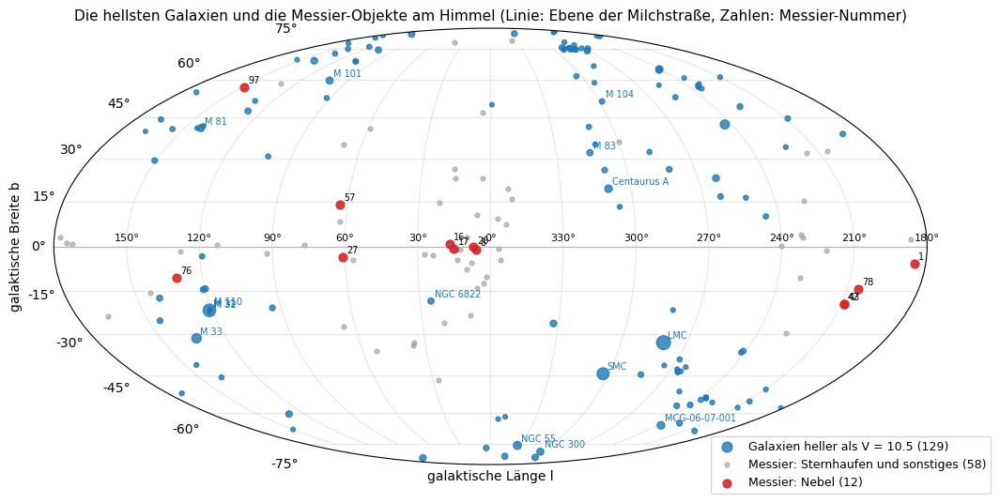

In [3]:
overview.sky_map(MAX_VMAG, MIN_SIZE)

**3. Galaxies: Eine Galaxie wählen – Eigenschaften und Entfernung**

Hier wird die Galaxie für die folgenden Schritte gewählt, ein Name aus der Tabelle in Schritt 1; Standard ist die Whirlpool-Galaxie M 51 mit ihrem Begleiter NGC 5195. Aus SIMBAD kommen alle veröffentlichten Entfernungen außer denen aus der Rotverschiebung, ihr Median ist die Entfernung; aus NED die Fluchtgeschwindigkeit. Daraus folgen Maßstab, Durchmesser und absolute Helligkeit.

M 51 steht 7.85 Mpc entfernt (Median aus sechs Messungen zwischen 6.2 und 8.4 Mpc), also ist 1′ = 2.28 kpc, der Durchmesser 20.7 kpc (zwei Drittel der Milchstraße) und M_V = −21.1. Das Hubble-Gesetz gäbe 8.57 Mpc. Schon die Fluchtgeschwindigkeit unterscheidet sich zwischen NED und SIMBAD um 77 km/s: Bei so nahen Galaxien ist das Hubble-Gesetz als Entfernungsmaß unsicher.

Galaxie:               M 51   (NED: MESSIER 051, Typ GPair)
Objekttyp:             Seyfert2   |   Hubble-Typ: SA
Koordinaten:           13h29m52.7s +47d11m42.9s
Helligkeit:            V = 8.36   B-V = 0.90   K = 5.50
Scheinbare Größe:      9.0' x 7.8'   (PA 28°)
Fluchtgeschwindigkeit: 600 km/s (NED; SIMBAD: 523 km/s)
Entfernung:            7.85 Mpc = 25.6 Millionen Lichtjahre (Median aus 6 Messungen ohne Rotverschiebung)
Maßstab:               1' = 2.28 kpc
Durchmesser:           20.7 kpc = 67,355 Lichtjahre
Absolute Helligkeit:   M_V = -21.11

Hubble-Gesetz: v/H0 = 8.57 Mpc gegen die Entfernungsleiter 7.85 Mpc
Eigenbewegung: v - H0·D = +50 km/s


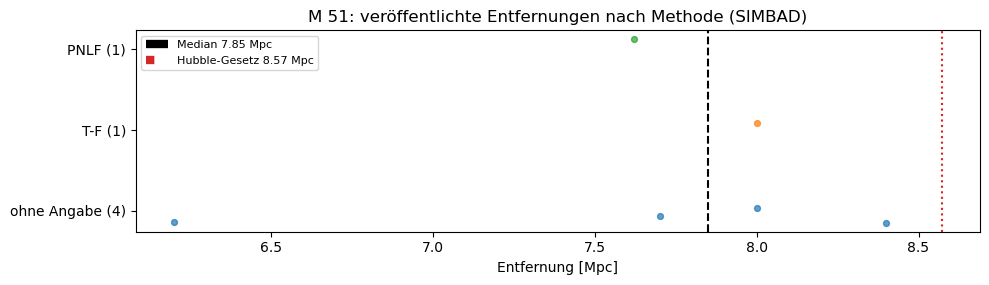

In [4]:
GALAXY = "M 51"    # ein Name aus der Tabelle in Schritt 1, z. B. "M 81", "M 101", "M 104"
photometry.target(GALAXY)

**4. Galaxies: Bilder in sechs Wellenlängenbereichen**

SkyView liefert sechs Bilder auf demselben Raster, vom Ultraviolett (GALEX) über das Optische (DSS2) bis 12 µm (WISE). Die Ellipse ist die Größe laut SIMBAD.

Im UV leuchten nur die Spiralarme mit ihren jungen Sternhaufen; der Begleiter NGC 5195 ist fast unsichtbar, weil dort kaum Sterne entstehen. Optisch sieht man Sternlicht mit Staubbändern, im nahen Infrarot eine glatte Galaxie aus alten Sternen, in der NGC 5195 fast so hell ist wie der Kern von M 51. Bei 12 µm zeichnet warmer Staub wieder die Arme nach, weil junge Sterne ihn heizen.

Lade 6 Bilder, 400x400 Pixel, Feld 14.5 arcmin ...


   GALEX Near UV  (400, 400)
   DSS2 Blue      (400, 400)
   DSS2 Red       (400, 400)
   2MASS-K        (400, 400)
   WISE 3.4       (400, 400)
   WISE 12        (400, 400)
Pixelgröße 2.17"


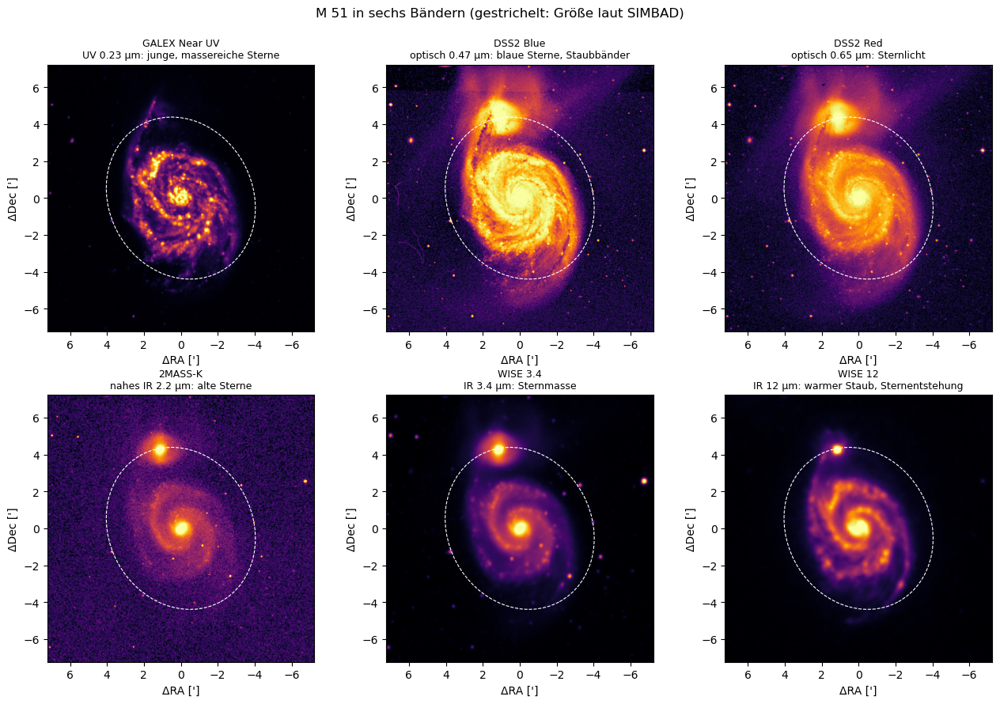

In [5]:
photometry.band_images()

**5. Galaxies: Farbbilder**

Links das optische Farbbild des Digitized Sky Survey, rechts ein Falschfarbenbild: Rot ist warmer Staub (12 µm), Grün sind alte Sterne (3.4 µm), Blau junge Sterne (UV). Ist der Dienst hips2fits des CDS nicht erreichbar (wie am 2026-11-13), wird das optische Bild aus den SkyView-Bildern DSS2 Rot und Blau zusammengesetzt.

Optisch sind die Arme blau mit hellen Sternhaufen, der Kern gelblich, an der Innenseite der Arme liegen dunkle Staubbänder. Im Falschfarbenbild leuchten die Arme blau-violett, wo junge Sterne und warmer Staub zusammenfallen; der Kern ist weiß, weil alle drei Bänder hell sind. NGC 5195 ist grün: nur alte Sterne, kein Staub, keine Sternentstehung.

hips2fits (CDS) nicht erreichbar: Farbbild aus SkyView DSS2 Rot und Blau


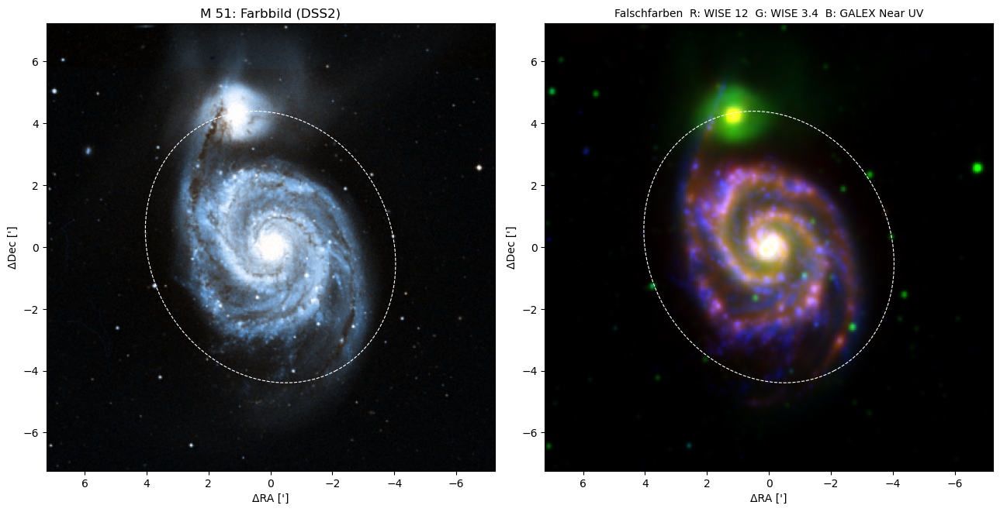

In [6]:
photometry.composites()

**6. Galaxies: Farbbilder im nahen und mittleren Infrarot**

Zwei weitere Mischungen zu den Bildern aus Schritt 5: nahes Infrarot aus 2MASS (K, H und J als Rot, Grün und Blau) und mittleres Infrarot aus WISE (12, 4.6 und 3.4 µm). SkyView rechnet jedes Band auf dasselbe Pixelgitter, deshalb passen sie ohne Ausrichtung aufeinander; jedes Band wird für sich mit einer Asinh-Kurve gestreckt, damit schwacher Rand und heller Kern zugleich sichtbar sind.

Im nahen Infrarot sind Staubbänder und blaue Sternhaufen verschwunden; es bleiben die alten Sterne, die den Kern und den Begleiter NGC 5195 am hellsten machen. Im mittleren Infrarot leuchten die Arme rötlich vom warmen Staub, den junge Sterne heizen; NGC 5195 und die Vordergrundsterne erscheinen türkis, weil bei ihnen das Sternlicht bei 3.4 und 4.6 µm überwiegt und warmer Staub fehlt.

6 Bilder, 14.5′ mit 600 Pixeln


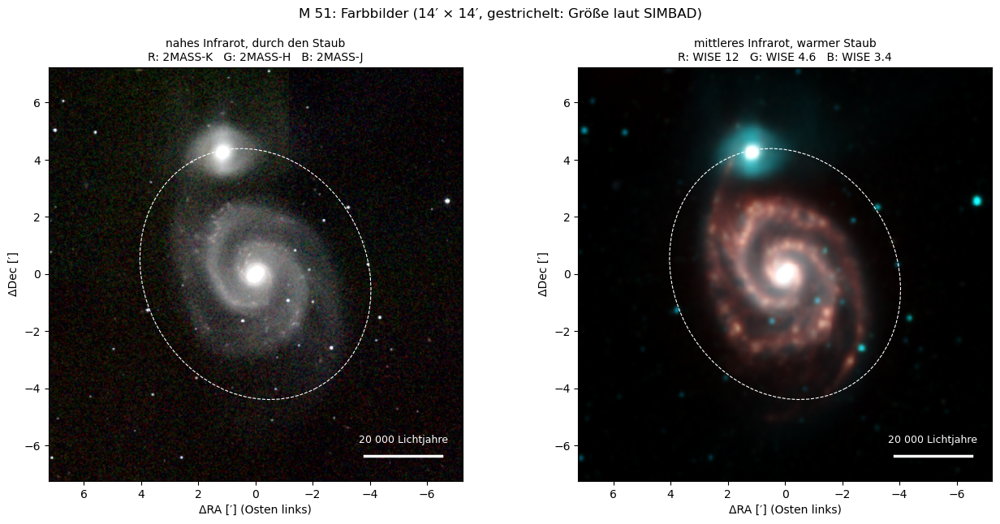

In [7]:
overview.ir_composites(GALAXY)

**7. Galaxies: Vom Röntgen- bis zum Radiobereich**

Neun Durchmusterungen vom Röntgenbereich (ROSAT) bis 21 cm (NVSS) in einem Feld von 1°. Viele dieser Karten lösen nur Bogenminuten auf (Hα 6′, IRIS 4′, Planck bei 30 GHz 32′), im engen Feld der übrigen Bilder wäre die Galaxie dort nur ein Fleck; das größere Feld zeigt dafür die Umgebung. Die Hα-Karte ist aus mehreren Durchmusterungen der Milchstraße zusammengesetzt.

M 51 ist im Röntgenbereich, bei 100 µm, 350 µm und 21 cm ein Fleck in der Mitte, bei 22 µm und im Optischen noch eine Spirale. In der Hα-Karte und bei 30 GHz fehlt die Galaxie: Die Hα-Karte zeigt nur das schwache Leuchten der Milchstraße im Vordergrund, und bei 32′ Auflösung gehen schwache Quellen im Rauschen und in den Schwankungen der Hintergrundstrahlung unter. Die Punkte im NVSS-Bild sind ferne Radioquellen, meist aktive Galaxienkerne.

9 Bilder, 60.0′ mit 360 Pixeln


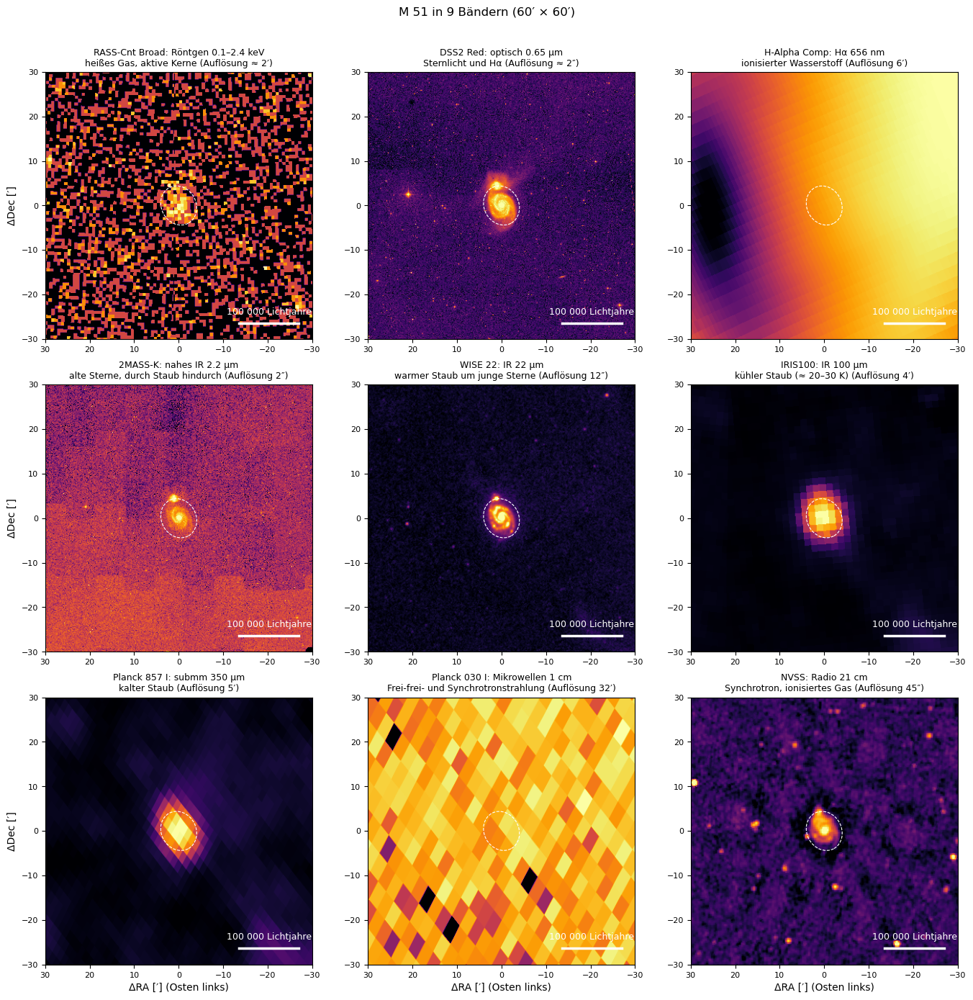

In [8]:
overview.wide_bands(GALAXY)

**8. Galaxies: Himmelshintergrund und radiales Profil**

Bei 3.4 µm folgt das Licht der Sternmasse, und Staub stört kaum. Gemittelt wird über Ellipsen mit der Form aus SIMBAD; der Himmel ist der Median außerhalb der Galaxie.

Das Profil fällt vom Zentrum über zwei Größenordnungen und erreicht bei 4.8′ das Rauschen des Himmels, nahe der großen Halbachse laut SIMBAD (4.5′). Zwischen 1′ und 2′ fällt es flacher: die Spiralarme. NGC 5195 liegt teilweise in den äußeren Ellipsen; der Median in den Ringen dämpft seinen Einfluss.

Himmel (Median außerhalb 1.1 a): 2.501, robuste Streuung 0.343  [WISE 3.4-Einheiten]
Profil: 40 Ringe bis 5.88'; Achsenverhältnis q = 0.86, PA = 28°
Zentrum 383.5, bei a: 3.70; Profil fällt unter 3 σ des Himmels bei 4.78'


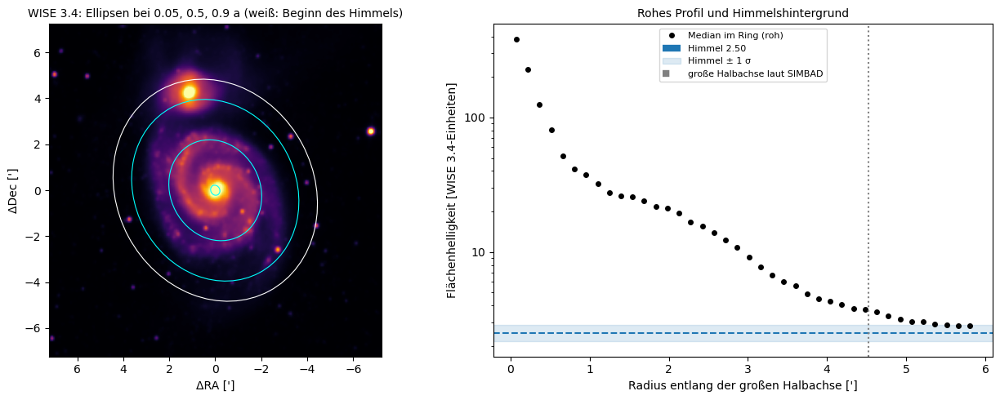

In [9]:
photometry.sky_profile()

**9. Galaxies: Die Farbkarte**

NUV − W1 vergleicht das UV-Licht junger Sterne mit dem Licht der Sternmasse; beide Bilder werden dafür auf ähnliche Auflösung geglättet und vom Himmel befreit.

Blau, also junge Sterne, folgt den Spiralarmen; rot sind das Zentrum, die Bereiche zwischen den Armen und NGC 5195 im Norden. Am blauesten ist die Galaxie um 6 kpc, wo die Arme am kräftigsten sind. Die Scheibe ist im Mittel 0.74 mag blauer als das Zentrum: junge Sterne in den Armen, alte im Bulge.

Pixel mit beiden Bändern über 3 σ: 36527
NUV - W1 im Zentrum (r < 0.1 a): +0.61 mag, in der Scheibe (0.3-0.7 a): -0.13 mag
Die Scheibe ist um 0.74 mag blauer als das Zentrum


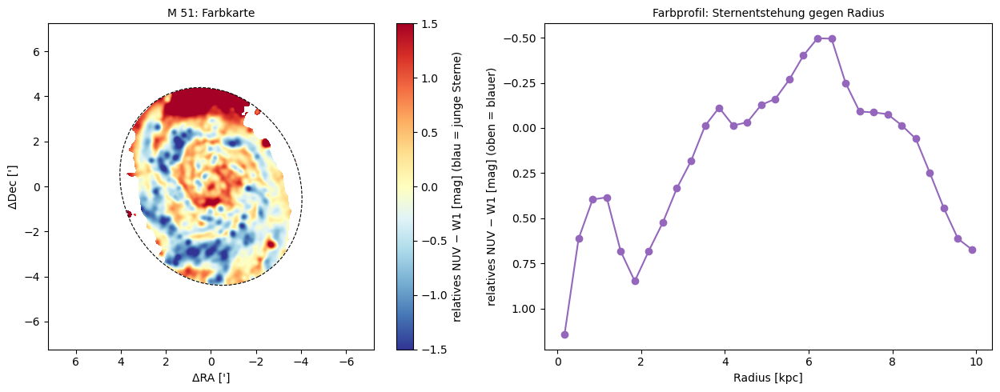

In [10]:
photometry.color_map()

**10. Galaxies: Spektren aus SDSS – drei Arten von Licht**

Der Sloan Digital Sky Survey hat mit Glasfasern von 3″ Durchmesser das Licht einzelner Stellen in Spektrographen geleitet, von 3800 bis 9200 Å. Gesucht werden alle Spektren um die gewählte Galaxie, deren Geschwindigkeit innerhalb von 600 km/s der Geschwindigkeit laut SIMBAD liegt. Ein Spektrum zeigt, woraus das Licht besteht: Sternlicht gibt ein glattes Kontinuum mit Absorptionslinien von Calcium, Magnesium und Natrium, leuchtendes Gas schmale Emissionslinien des Wasserstoffs (Hα, Hβ) und die „verbotenen“ Linien von Sauerstoff, Stickstoff und Schwefel, die nur in sehr dünnem Gas entstehen.

SDSS hat um M 51 fünf passende Spektren, auf den Kern von M 51 selbst keines. Faser 1 liegt auf dem Kern des Begleiters NGC 5195, gut 4′ nördlich: ein Kontinuum, das zum Roten hin ansteigt, mit den Absorptionslinien von Natrium und Magnesium, also das Licht alter, kühler Sterne; an Emission ist nur [N II] zu sehen. Die Fasern 2 bis 4 liegen auf dem nördlichen Spiralarm: blaues Kontinuum junger Sterne und kräftige Emissionslinien des Gases in Sternentstehungsgebieten. Faser 5 ist ein Stern der Milchstraße im Vordergrund (Spektraltyp M3 III), dessen Geschwindigkeit nahe 0 noch ins Fenster fällt.

M 51: Geschwindigkeit 523 km/s laut SIMBAD; im Kasten von 9.0′ mit ±600 km/s 5 SDSS-Spektren (4 GALAXY, 1 STAR)
5 von 5 Spektren geladen (Cache M_51/sdss/)
1 Bilder, 14.5′ mit 600 Pixeln


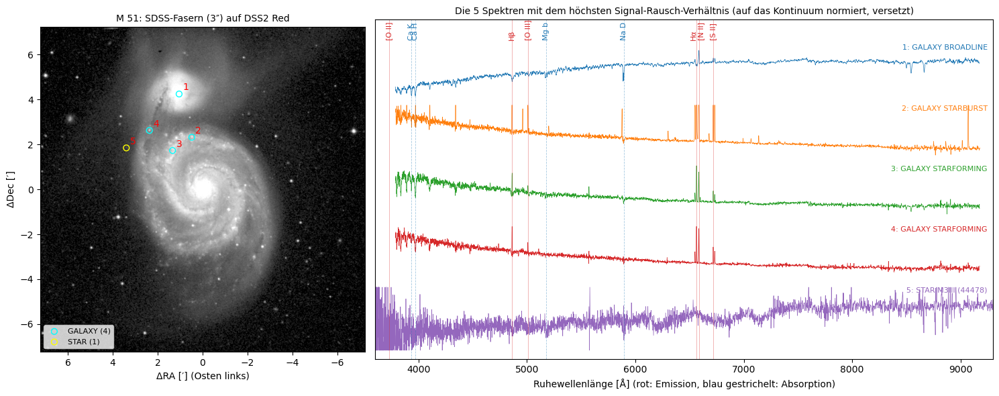

In [11]:
overview.sdss_spectra(GALAXY)

**11. Galaxies: H-II-Regionen – M 101 und seine SDSS-Spektren**

Wo Sterne entstehen, leuchten H-II-Regionen, Gaswolken, die junge, heiße Sterne ionisieren. Aus wenigen hellen Linien liest man Dichte, Staub, was das Gas ionisiert und wie viel Sauerstoff es enthält; der Sauerstoff ist das Gedächtnis früherer Sterngenerationen. Der Sloan Digital Sky Survey (SDSS) hat zufällig Dutzende Fasern auf die Spiralgalaxie M 101 gesetzt, weil seine Zielauswahl die hellen Knoten in den Armen für eigene Galaxien hielt.

M 101 steht 6.83 Mpc entfernt (1′ = 1.99 kpc) und ist fast von oben zu sehen. 57 Spektren haben die passende Geschwindigkeit; die cyanen Fasern sitzen fast alle auf hellen Knoten in den Armen, die gelben (Klasse STAR) liegen verstreut. Das Spektrum im Zentrum zeigt Sternlicht mit Absorptionslinien und darauf Hβ, Hα, [N II] und [S II].

M 101: Hubble-Typ S_AB, v_sys = 243 km/s, D = 6.83 Mpc (1' = 1.99 kpc), Durchmesser 21.9', q = 0.95
57 SDSS-Spektren geladen; Klassen der Pipeline: {'GALAXY': 50, 'STAR': 7}
Mit Linienflüssen im MPA-JHU-Katalog: 57
hips2fits (CDS) nicht erreichbar: Farbbild aus SkyView DSS2 Rot und Blau


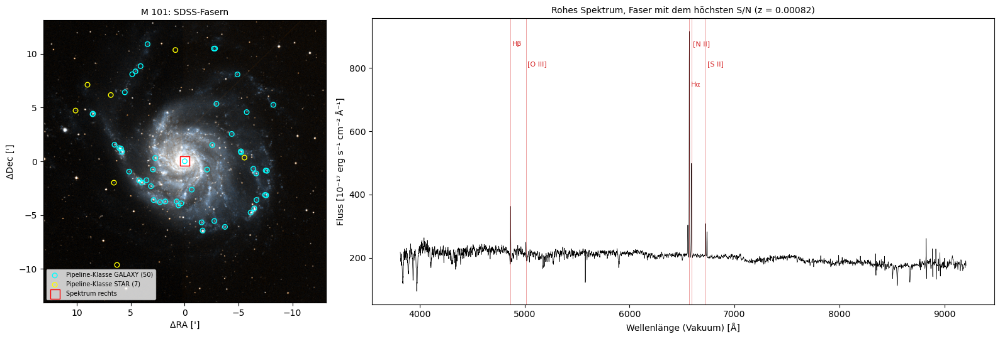

In [12]:
hiiregions.sdss_spectra()

**12. Galaxies: Warps – Galaxien in Kantenlage**

Die Scheibe einer Spiralgalaxie ist innen meist eben, außen aber oft verbogen wie eine Hutkrempe, auch die Milchstraße. Eine ungestörte Scheibe sollte eben bleiben; ein Warp verrät deshalb, was um die Galaxie geschieht: ein gekippter Halo aus Dunkler Materie, einfallendes Gas mit anderem Drehimpuls oder Gezeitenkräfte von Begleitern. Hier wird die Verbiegung in Bildern der DESI Legacy Surveys gemessen und mit dem Katalog von Sánchez-Saavedra et al. (2003) verglichen; Beispiel ist ESO 240-011.

ESO 240-011 in mehreren Bändern ist eine dünne, gerade Nadel. Im UV leuchtet die Scheibe gleichmäßig schmal, weil junge Sterne nahe der Mittelebene sitzen, optisch ist sie innen dicker und gelblich. Mit bloßem Auge ist in keinem Band eine Verbiegung zu sehen; dafür braucht es die Messung.

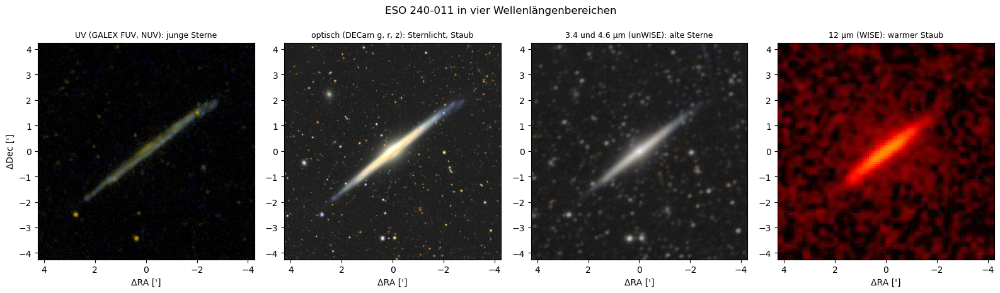

In [13]:
warps.load()

**13. Galaxies: Bild und Katalogdaten**

SIMBAD liefert Position, Größe, Positionswinkel und die Entfernungen ohne Rotverschiebung, der Legacy-Survey-Viewer den Ausschnitt im r-Band.

Die Galaxie ist 5.3′ lang und 44.3 Mpc entfernt (meist Tully-Fisher), ein Pixel entspricht 137 pc. Im r-Band ist sie eine schmale Scheibe mit hellem Zentrum; rundherum liegen Vordergrundsterne und kleine Hintergrundgalaxien, die bei der Messung herausfallen müssen.

ESO 240-011: RA 354.4559, Dec -47.7273, z = 0.00951, große Achse 5.3'
D = 44.3 Mpc (Median aus 6 Messungen ohne Rotverschiebung; cz/H0 = 40.7 Mpc)
1 px = 0.638" = 137 pc, Bild 800 x 800 px


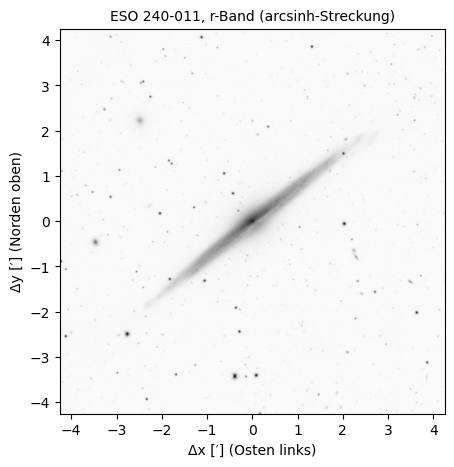

In [14]:
warps.image()

**14. Galaxies: Spine-Fit**

In jeder Gruppe von drei Bildspalten gibt ein Gauß-Fit die Höhe der hellsten Stelle, die Spine. Spalten mit wenig Signal, Sternen oder Ausreißern fallen weg.

Von 207 Spalten bleiben 170. Die Spine ist keine Gerade: in der Mitte eine flache Kuppel, nach Osten fällt sie gleichmäßig um 5 Pixel ab, nach Westen um 3, und ganz außen knickt sie auf der Westseite steil ab, bei kleinem Signal.

207 Spalten gefittet, 170 behalten (SNR > 5.0, Ausreißer entfernt)


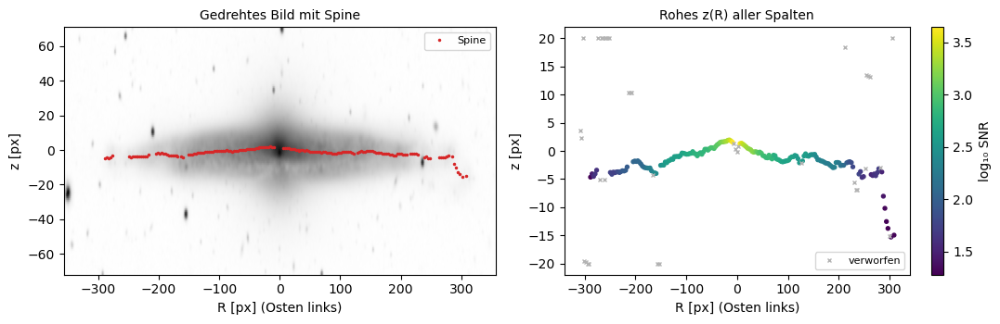

In [15]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    warps.orientation()                     # Himmel abziehen und Bild drehen
warps.spine_fit()

**15. Galaxies: Form des Warps – Referenzebene, Staub oder Geometrie?**

Durch die innere Spine wird eine Gerade gelegt; der Abstand aller Punkte von ihr ist das Warp-Profil. Für jede Seite folgen Amplitude und Winkel im äußersten Viertel und daraus die Form: S (die Seiten biegen gegensinnig), U (gleichsinnig) oder einseitig. Staub schwächt blaues Licht stärker als rotes. Eine echte Verbiegung erscheint in allen Bändern gleich, ein Staubeffekt nicht; dieselbe Messung läuft deshalb auch im g- und z-Band.

Die Ostseite liegt außen 842 pc unter der Ebene (Winkel −1.5°), die Westseite nur 255 pc: ein einseitiger Warp. Die Einordnung ist aber empfindlich; mit einem größeren inneren Bereich würde ein U daraus. Fest steht, dass die Ostseite um etwa 0.8 kpc nach unten verbogen ist. Die Profile in g, r und z liegen fast überall aufeinander, auch auf der verbogenen Ostseite: Die Verbiegung ist geometrisch. Nur die äußerste Westspitze unterscheidet sich, und allein sie macht im g-Band einen U-Warp aus der Form.

Innere Gerade: a = -0.0097 (Restdrehung -0.55 Grad), b = +0.06 px
Streuung innen s = 153 pc
Ostseite: z_warp = -842 pc (5.5 s) bei R = 32.9 kpc, Warp-Winkel -1.5 Grad
Westseite: z_warp = -255 pc (1.7 s) bei R = 37.7 kpc, Warp-Winkel -0.4 Grad
S-Anteil 294 pc, U-Anteil 549 pc  ->  L-Warp (einseitig), klar


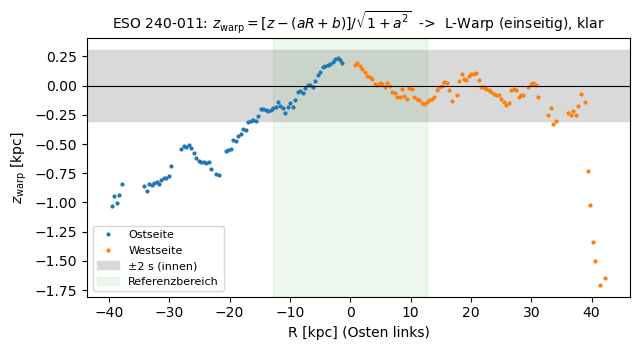

g: Ost  -799 pc, West  -987 pc, s = 225 pc  ->  U-Warp, klar
r: Ost  -842 pc, West  -255 pc, s = 153 pc  ->  L-Warp (einseitig), klar


z: Ost  -842 pc, West    -3 pc, s = 113 pc  ->  L-Warp (einseitig), klar


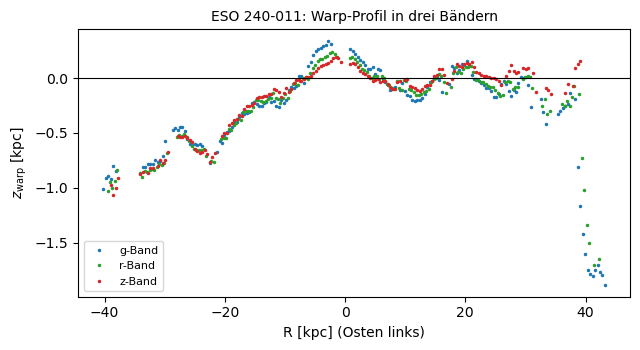

In [16]:
warps.warp_shape()
warps.dust_or_geometry()

**16. Nebulae: Die Datenbank SIMBAD – die Nebel des Messier-Katalogs**

Charles Messier hat im 18. Jahrhundert die hellsten verwaschenen Flecken des Nordhimmels gesammelt, damit man sie nicht mit Kometen verwechselt: 110 Objekte, Galaxien, Sternhaufen und Nebel. SIMBAD liefert zu jedem Typ, Lage und Größe; die Karte zeigt sie in galaktischen Koordinaten mit der Ebene der Milchstraße als Mittellinie. Aus dieser Liste wählt man im nächsten Schritt einen Nebel.

SIMBAD führt 56 Sternhaufen, 40 Galaxien, 12 Nebel und 2 sonstige Objekte. Vier der zwölf Nebel (M 8, 16, 17, 20) stehen dort unter dem Sternhaufen in ihrer Mitte; der Code trägt sie von Hand als Nebel ein. Die Nebel liegen fast alle nahe der Ebene der Milchstraße, denn dort entstehen und sterben die Sterne; nur der planetarische Nebel M 97 steht weit darüber. Die Galaxien meiden diesen Streifen, weil der Staub der Milchstraße den Blick nach draußen verdeckt, und drängen sich oben im Virgo-Haufen. Der Orionnebel M 42 ist gleich das Beispiel; die planetarischen Nebel M 27 und M 57 und der Krebsnebel M 1 kommen später wieder.

110 Messier-Objekte: 56 Sternhaufen, 40 Galaxien, 12 Nebel, 2 sonstige
In Klammern der SIMBAD-Typ und die Größe (große Achse in Bogenminuten).

Nebel (12):
  M 1 (SNR, 7′), M 8 (OpC, 90′), M 16 (OpC, 35′), M 17 (OpC, 11′), M 20 (OpC, 28′), M 27 (PN, 7′), M 42 (HII,
  66′), M 43 (HII), M 57 (PN, 1′), M 76 (PN, 2′), M 78 (RNe), M 97 (PN, 3′)


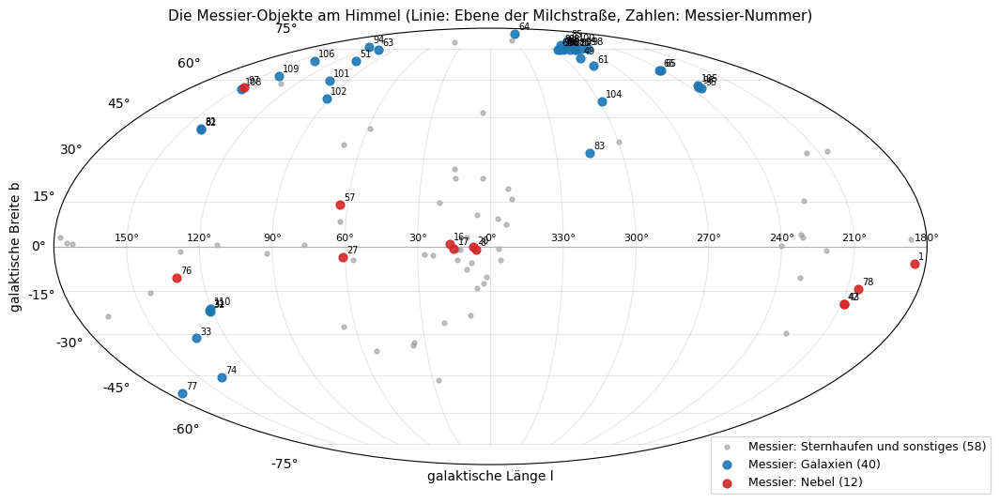

In [20]:
messier.sky()

**17. Nebulae: Einen Nebel wählen – Eigenschaften**

Hier wird der Nebel für die nächsten beiden Schritte gewählt, ein Name aus der Liste oben oder jeder andere, den SIMBAD kennt. Standard ist der Orionnebel M 42, das nächste große Gebiet, in dem massereiche Sterne entstehen, mit bloßem Auge im Schwert des Orion zu sehen. In seiner Mitte steht das Trapez; einer seiner Sterne, θ¹ Orionis C, ein O-Stern mit rund 30 Sonnenmassen, ionisiert mit seinem UV-Licht die Oberfläche einer dichten Molekülwolke. SIMBAD liefert Typ, Koordinaten, Größe und die veröffentlichten Entfernungen; daraus folgen der Maßstab und das Feld der Farbbilder (1.6-mal die Größe, höchstens 1°).

M 42 ist in SIMBAD eine H-II-Region von 66′, gut zwei Vollmonde, in 473 pc Entfernung (1 543 Lichtjahre, Median aus vier Messungen ohne Rotverschiebung); 1′ entspricht dort 0.4 Lichtjahren, der ganze Nebel 30 Lichtjahren. Die Farbbilder zeigen das innere Grad mit 4.5″ pro Pixel.

In [21]:
NEBULA = "M 42"    # ein Nebel aus der Liste oben oder jeder Name, den SIMBAD kennt, z. B. "M 1", "M 57", "Helix Nebula"
messier.target(NEBULA)

M 42
Typ:          Nebel, HII Region (HII)
Koordinaten:  05h35m17s -05d23m15s  (RA 83.8201°, Dec -5.3876°)
Größe:        66.0′ × 66.0′, PA 90°  (laut SIMBAD)
Entfernung:   473 pc = 1 543 Lichtjahre  (Median aus 4 Messungen ohne Rotverschiebung)
Maßstab:      1′ = 0.4 Lichtjahre; große Achse 30 Lichtjahre
Bildfeld:     60.0′ × 60.0′ mit 800 × 800 Pixeln (4.5″ pro Pixel)


**18. Nebulae: Vom Röntgen- bis zum Radiobereich**

Dieselben neun Durchmusterungen wie bei den Galaxien, vom Röntgenbereich (ROSAT) bis 21 cm (NVSS), in einem Feld von dreimal der Größe des Nebels, höchstens 3°: Röntgen zeigt junge, aktive Sterne, Hα das ionisierte Gas, das nahe Infrarot Sterne durch den Staub hindurch, das ferne Infrarot und der Submillimeterbereich kalten Staub, das Radio die Strahlung des ionisierten Gases.

Röntgen und 2MASS K zeigen in der Mitte einen hellen Punkt, die jungen Sterne des Trapezes. Optisch und im warmen Staub (22 und 100 µm) ist der Nebel ein heller Fleck mit einem Ausläufer nach Norden zu M 43, bei 350 µm wird daraus ein langes Band von Nord nach Süd: die Molekülwolke Orion A, deren Spitze der Nebel ist. Bei 30 GHz leuchtet das ionisierte Gas als Fleck von der Größe der Auflösung (32′). Drei Bilder zeigen Grenzen der Karten: Hα ist im Kern zu einem waagrechten Streifen verschmiert, vermutlich weil die Karte dort übersättigt ist, 2MASS K ist aus Kacheln zusammengesetzt, und NVSS sieht als Interferometer keine großen Strukturen, um die helle Quelle liegen Ringe.

9 Bilder, 180.0′ mit 360 Pixeln


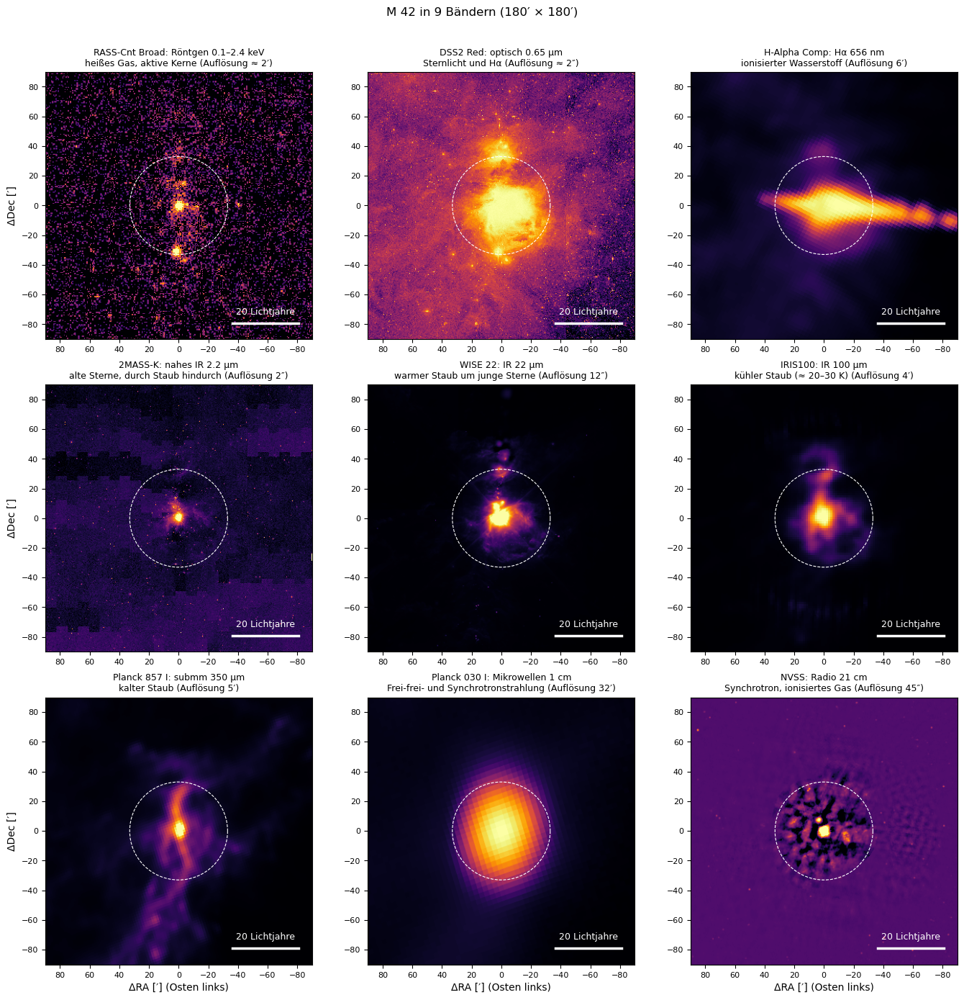

In [22]:
messier.wide_bands()

**19. Nebulae: Farbbilder in drei Wellenlängenbereichen**

Je drei Bänder werden als Rot, Grün und Blau gemischt: optisch aus Fotoplatten (DSS2 rot und blau, Grün als ihr Mittel), nahes Infrarot aus 2MASS (K, H, J) und mittleres Infrarot aus WISE (12, 4.6, 3.4 µm).

Optisch leuchtet das ionisierte Gas, auf den Fotoplatten im Kern übersättigt und von dunklen Staubbändern durchzogen. Im nahen Infrarot verschwindet der Nebel fast; stattdessen erscheint ein dichter Haufen von Sternen, die in oder hinter Staub stecken. Im mittleren Infrarot leuchtet warmer Staub mit großen Molekülen (PAH) in Fasern und Bögen; die blauen Streifen in der Mitte sind übersättigte Pixel von WISE.

9 Bilder, 60.0′ mit 800 Pixeln


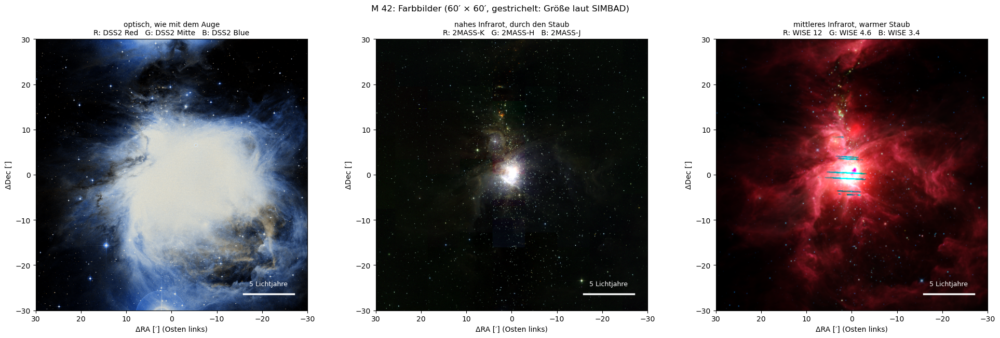

In [23]:
messier.color_images()

**20. Nebulae: ρ Ophiuchi – eine Dunkelwolke auf drei Wegen**

1784 stieß Herschel im Skorpion auf eine Stelle ohne Sterne und hielt sie für ein Loch im Himmel. Erst Barnard und Wolf zeigten, dass es Wolken sind, die das Licht dahinter verschlucken, und Trumpler 1930, dass der Staub die ganze Milchstraße durchzieht. Die Wolke um ρ Ophiuchi ist eine der nächsten; in ihrem dichten Kern L1688 sitzen einige hundert junge Sterne, die man nur im Infraroten sieht. Man kann sie auf drei Wegen kartieren: mit den Farben der Sterne dahinter (2MASS), mit der Wärmestrahlung des Staubs (IRAS, Planck) und mit der Entfernung, ab der Gaia-Sterne gerötet sind.

Geladen werden 102 443 Sterne aus 2MASS im Feld und 51 321 in einem Kontrollfeld mit wenig Staub, 15 340 Gaia-Sterne mit guter Parallaxe und Extinktion, Bilder in sechs Bändern vom Blauen bis 850 µm und ein Rechengitter mit 3′ pro Pixel. Dazu die Umrechnungen der Farben in Extinktion: A_V = 15.87 · E(H−K) und 9.35 · E(J−H).

In [24]:
ophiuchus.load()

2MASS: 102443 Quellen im Feld, 51321 im Kontrollfeld (E(B−V) = 0.140 nach Schlafly & Finkbeiner)
Gaia DR3 mit Parallaxe S/N > 5 und A_G: 15340 Sterne
Bilder: DSS2 Blue 200², DSS2 Red 200², WISE 12 200², IRIS100 200², Planck 857 I 200², Planck 353 I 200² | Rechengitter 60² zu 3′
Medianwerte im Feld [MJy/sr]: IRIS100 118.4, Planck 857 I 57.7, Planck 545 I 17.8, Planck 353 I 4.9
Rechengitter: Mitte (247.0, -24.2), 3.0′ pro Pixel; A_V/E(H−K) = 15.87, A_V/E(J−H) = 9.35, E(J−H)/E(H−K) = 1.70


**21. Nebulae: Die Wolke in sechs Bändern**

Dasselbe Feld von 3° × 3° in sechs Bändern: Fotoplatten in Blau und Rot, WISE bei 12 µm, die Wärmestrahlung des Staubs bei 100, 350 und 850 µm. Markiert sind die hellen B-Sterne ρ Oph, HD 147889 und 22 Sco.

Im Blauen ist die Wolke ein dunkles Band mit fehlenden Sternen, um die hellen Sterne leuchten blaue Reflexionsnebel (Staub streut blaues Licht stärker). Bei 12 µm leuchtet nur Staub, den ein heißer Stern direkt bestrahlt. Im fernen Infrarot ist die Wolke hell statt dunkel: Bei 100 µm liegt das Maximum am warmen Staub um HD 147889, bei 850 µm im kalten, dichten Kern daneben, wo die meiste Masse ist.

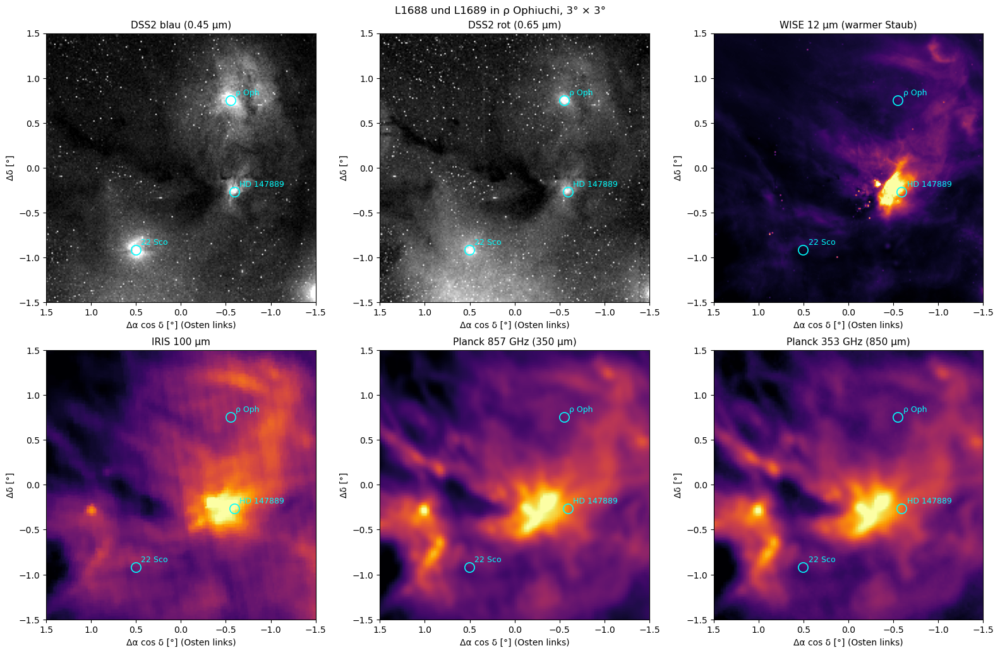

DSS2 Blue     : Median   3935.000, 99.5. Perzentil  11380.015
DSS2 Red      : Median   4494.000, 99.5. Perzentil   9822.080
WISE 12       : Median    924.137, 99.5. Perzentil   2425.351
IRIS100       : Median    118.321, 99.5. Perzentil   1773.666
Planck 857 I  : Median     57.783, 99.5. Perzentil    529.467
Planck 353 I  : Median      0.017, 99.5. Perzentil      0.166


In [25]:
ophiuchus.bands()

**22. Nebulae: Sterne in Richtung der Wolke**

Gezählt werden die Sterne aus 2MASS und aus Gaia pro Pixel von 3′ und mit der Helligkeit bei 857 GHz verglichen.

Je mehr Staub strahlt, desto weniger Sterne kommen durch. In den 5 % hellsten Planck-Pixeln sieht 2MASS noch 4.9 Sterne pro Pixel, Gaia nur 0.3, weil die Extinktion im Optischen zehnmal größer ist als im Infraroten. 2MASS taugt deshalb für die Extinktionskarte, Gaia nur für den Rand der Wolke und die Sterne davor.

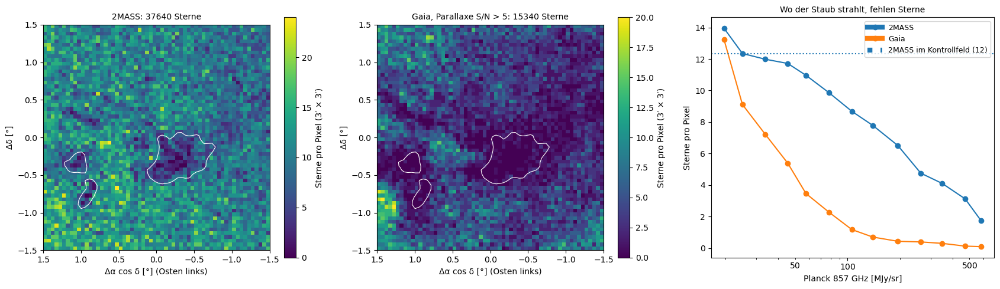

2MASS nach Qualitätsschnitt: 37640 von 102443 im Feld, 15489 von 51321 im Kontrollfeld; mit J: 96%
Sterne pro Pixel: 2MASS Median 10 (Kontrollfeld 12.3), leere Pixel 10; Gaia Median 3, leere Pixel 460
In den 5 % hellsten Planck-Pixeln: 2MASS 4.9, Gaia 0.3 Sterne pro Pixel


In [26]:
ophiuchus.stars()

**23. Nebulae: H-II-Regionen – die Gaswolken von M 101 in SDSS**

H-II-Regionen sind Gaswolken, die junge, heiße Sterne ionisieren und zum Leuchten bringen; aus ihren Linien liest man, wie viel Sauerstoff das Gas enthält. Wie hell eine Linie pro Ion leuchtet, hängt aber exponentiell von der Temperatur ab, und die lässt sich messen: Dasselbe Ion strahlt aus zwei verschieden hohen Niveaus, und das Verhältnis der Linien wirkt als Thermometer. Die obere Linie ist 100- bis 500-mal schwächer; das Projekt CHAOS hat sie mit dem Large Binocular Telescope gemessen. Hier wird in den Spektren, die der Sloan Digital Sky Survey (SDSS) auf die Galaxie M 101 gelegt hat, nach diesen schwachen Linien gesucht.

Bei SDSS liegen 76 Spektren um die Galaxie, 54 auf Gas und 22 auf Vordergrundsternen. Die Fasern sitzen auf den blauen Knoten der Spiralarme und verteilen sich bis an den Rand der Scheibe, im Mittel weiter außen als die 102 CHAOS-Regionen; 14 Fasern treffen eine CHAOS-Region innerhalb von 3″.

Zentrum aus den CHAOS-Namen: RA 210.80207°, Dec 54.34886°; R25 = 14.4′ = 31.0 kpc bei 7.4 Mpc
Kontrolle: eigene Abstände R/R25 minus CHAOS: höchstens 0.0018
CHAOS: 102 Regionen, 74 mit mindestens einer gemessenen Temperatur, 77 mit O/H
SDSS: 76 Spektren; Klassen {'GALAXY': 54, 'STAR': 22}; Spektrographen {'SDSS': 52, 'BOSS': 24}
Fasern auf Gas: 54 (SDSS 48, BOSS 6); innerhalb von 3″ einer CHAOS-Region: 14


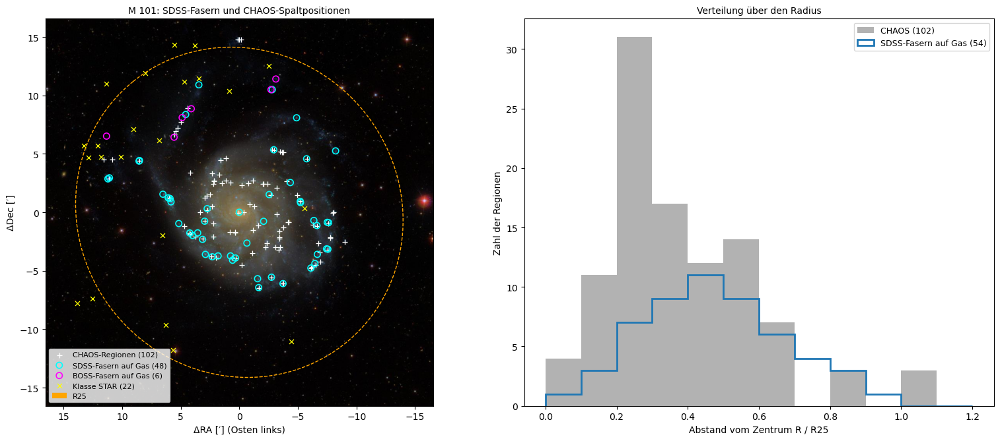

In [28]:
hii.regions()

**24. Nebulae: Erster Blick auf die schwachen Linien**

Das rohe Spektrum der Faser auf der hellen, metallarmen Riesenregion NGC 5471, vergrößert um die vier Temperaturlinien ([O III] 4363, [N II] 5755, [S III] 6312, [O II] 7320/7330).

Die starken Linien ragen weit über das Licht der Sterne. Bei [O III] 5007 und Hα fehlen die Werte im Kern: Der Detektor war gesättigt, ausgerechnet in der hellsten Region. [O III] 4363 erreicht hier ein Viertel der Höhe von Hγ, weil das Gas heiß ist; [N II] 5755 hebt sich kaum aus dem Rauschen. In metallreichen Regionen wird 4363 hundertmal schwächer.

Faser 1491914454806325248 (SDSS), 4.4″ von einer CHAOS-Position in NGC 5471, R/R25 = 0.82
  Hb       : 0 maskierte Pixel im Linienkern
  OIII5007 : 5 maskierte Pixel im Linienkern
  Ha       : 4 maskierte Pixel im Linienkern
  OIII4363 : 0 maskierte Pixel im Linienkern
Spitzenhöhe über dem Kontinuum relativ zu Hγ: OIII4363 0.225, NII5755 0.003, SIII6312 0.026, OII7320 0.026, OII7330 0.021


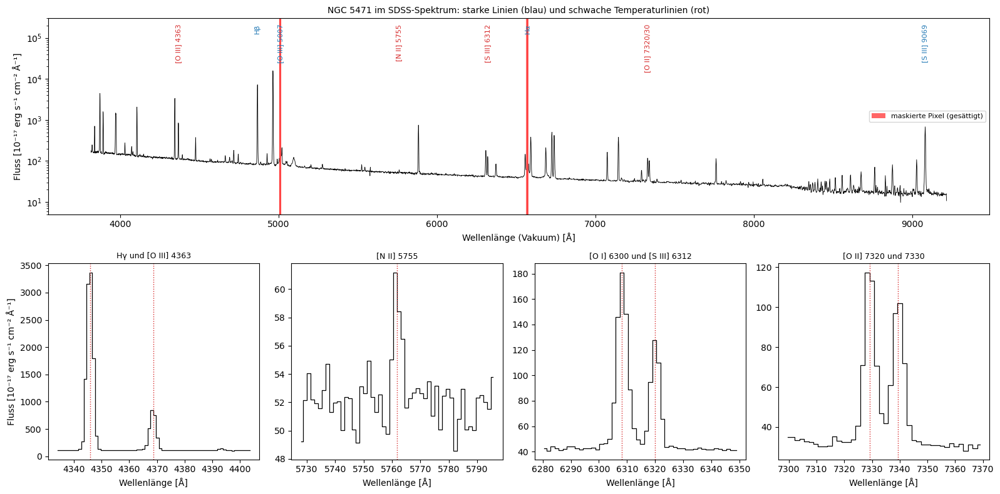

In [29]:
hii.weak_lines()

**25. Nebulae: Planetarische Nebel – Kataloge und Atomdaten**

Planetarische Nebel begleiten das Ende fast aller Sterne bis acht Sonnenmassen, vermutlich auch das der Sonne: Der Nebel ist die abgestoßene Hülle, der Stern in der Mitte der freigelegte Kern auf dem Weg zum Weißen Zwerg. Herschel nannte sie 1785 so, weil sie im Fernrohr wie Uranus aussahen. Geladen werden die Zentralsterne in Gaia (Chornay und Walton 2021), der Strasbourg-ESO-Katalog mit Linienstärken und Expansionsgeschwindigkeiten, Entwicklungswege der Zentralsterne, ein Katalog von Temperaturen aus der Literatur, zwei Kataloge von Nebeln in M 31 und Atomdaten für Wasserstoff und Helium.

Die Ausgabe zählt die Zeilen jedes Katalogs: 2117 Nebel mit Gaia-Kandidat, 1143 im Strasbourg-ESO-Katalog (614 mit Geschwindigkeiten), 618 Temperaturen aus der Literatur, 429 und 3300 Nebel in M 31. Dazu die Atomkonstanten (Hα/Hβ ohne Staub 2.863) und sechs Entwicklungswege; deren Leuchtkraft auf dem Plateau gibt über die Kern-Leuchtkraft-Beziehung die Kernmasse auf 0.01 bis 0.03 Sonnenmassen genau zurück.

In [30]:
planetary.load()

Chornay & Walton 2021       2117 Zeilen
Strasbourg-ESO: Nebel       1143 Zeilen
  mit Durchmesser           1138 Zeilen
  mit Hβ-Fluss               991 Zeilen
  mit Linienstärken         1045 Zeilen
  mit Geschwindigkeiten      614 Zeilen
  mit Zentralstern           692 Zeilen
Vassiliadis & Wood 1994      720 Zeilen
Weidmann et al. 2020         618 Zeilen
Ciardullo et al. 1989        429 Zeilen
Merrett et al. 2006         3300 Zeilen
k(λ) = A_λ/E(B−V): Hβ 3.61, Hα 2.54, 5007 3.47, 4686 3.79, V 3.11
Hα/Hβ ohne Staub = 2.863;  α_eff(Hβ)/α_B = 0.119;  α_eff(4686)/α_B(He⁺) = 0.236
Spuren bei Z = 0.016: Anfangsmassen [1.0, 1.5, 2.0, 2.5, 3.5, 5.0] M☉, Kernmassen [0.569, 0.597, 0.633, 0.677, 0.754, 0.9] M☉, 270 Punkte
  M_i = 1.0: Plateau log L = 3.56, Kernmasse aus L = 59250 (M_c − 0.495): 0.556 (Tabelle 0.569)
  M_i = 1.5: Plateau log L = 3.74, Kernmasse aus L = 59250 (M_c − 0.495): 0.588 (Tabelle 0.597)
  M_i = 2.0: Plateau log L = 3.89, Kernmasse aus L = 59250 (M_c − 0.495): 0.627 (Tab

**26. Nebulae: Vier Nebel im Bild**

Farbbilder aus Pan-STARRS (Filter g, r, i) von vier bekannten Nebeln, vom kleinen, hellen Blauen Schneeball NGC 7662 über den Ringnebel M 57 und den Hantelnebel M 27 zum großen, blassen Abell 39. Markiert sind der Zentralstern aus Gaia, der Radius des Nebels und ein Balken von 0.1 pc in der Gaia-Entfernung.

NGC 7662 hat 0.13 pc Radius, M 57 0.17 pc, M 27 und Abell 39 je 0.45 pc; wachsen alle gleich schnell, ist NGC 7662 der jüngste. Blau ist [O III], grün Hα und [N II]: In M 57 und M 27 sitzt das Blaue innen, wo das Gas nahe am Stern höher ionisiert ist. Im kleinen NGC 7662 geht der Zentralstern im Nebel fast unter, im großen Abell 39 ist er der hellste Punkt.

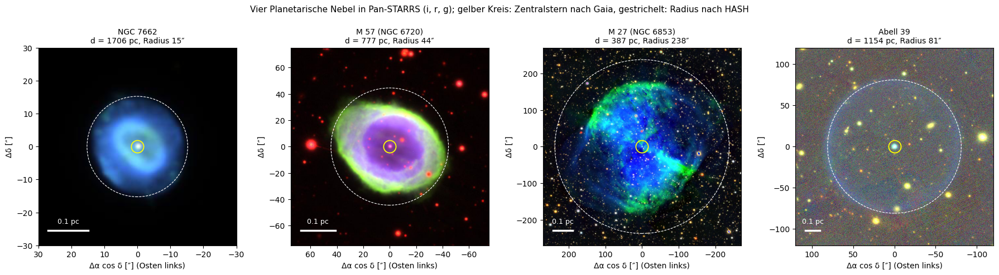

          Nebel        PNG     G  Parallaxe_mas    SN    d_pc  Radius_as  Radius_pc
       NGC 7662 106.5-17.6 13.93           0.57 17.04 1706.48      15.25       0.13
M 57 (NGC 6720) 063.1+13.9 15.65           1.27 29.01  777.24      44.50       0.17
M 27 (NGC 6853) 060.8-03.6 14.04           2.57 68.92  386.55     237.50       0.45
       Abell 39 047.0+42.4 15.57           0.85 20.14 1153.54      81.00       0.45


In [31]:
planetary.images()

**27. Nebulae: Kataloge und Auswahl**

Die Kataloge werden über die Bezeichnung der Nebel verknüpft. Die Arbeitsstichprobe sind Nebel mit sicher zugeordnetem Zentralstern und guter Parallaxe (Signal-Rausch über 5).

Von 2117 Nebeln mit Gaia-Kandidat haben 291 eine gute Parallaxe. Sie liegen nicht gleichmäßig: 83 % aller Nebel liegen nahe der Milchstraßenebene, aber nur 54 % der Arbeitsstichprobe, weil die Nebel in Bulge und Ebene zu weit und zu stark gerötet sind. Jeder spätere Schritt arbeitet mit einer kleineren Teilmenge: 112 haben einen Hβ-Fluss, 88 dazu die Helligkeit des Sterns, 47 die Linie He II 4686, 92 Radius und Expansionsgeschwindigkeit.

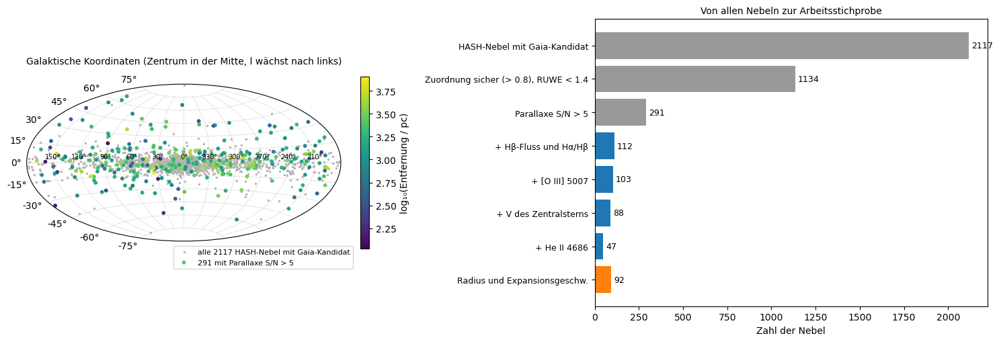

HASH-Nebel mit Gaia-Kandidat            2117
Zuordnung sicher (> 0.8), RUWE < 1.4    1134
Parallaxe S/N > 5                        291
+ Hβ-Fluss und Hα/Hβ                     112
+ [O III] 5007                           103
+ V des Zentralsterns                     88
+ He II 4686                              47
Radius und Expansionsgeschw.              92
Gesättigtes 5007 durch 2.98 × 4959 ersetzt: 30 Nebel im ganzen Katalog
Anteil mit |b| < 10°: alle 83%, Arbeitsstichprobe 54%


In [32]:
planetary.catalogs()

**28. Nebulae: Größe und kinematisches Alter**

Winkelradius mal Entfernung gibt den Radius, die Aufspaltung der Linie [O III] die Expansionsgeschwindigkeit (Vorder- und Rückseite der Hülle bewegen sich in entgegengesetzte Richtungen). Radius durch Geschwindigkeit ist das kinematische Alter.

Die Radien reichen von 0.07 bis 0.85 pc (Median 0.19 pc), die Geschwindigkeiten meist von 8 bis 45 km/s. Die 92 Alter haben einen Median von 9200 Jahren; ältere Nebel als etwa 50 000 Jahre sind so dünn, dass man sie nicht mehr sieht. Größere Nebel wachsen schneller, wie in Modellen, in denen der Wind des Sterns die Schale beschleunigt. NGC 7662 ist 4500 Jahre alt, M 27 29 000.

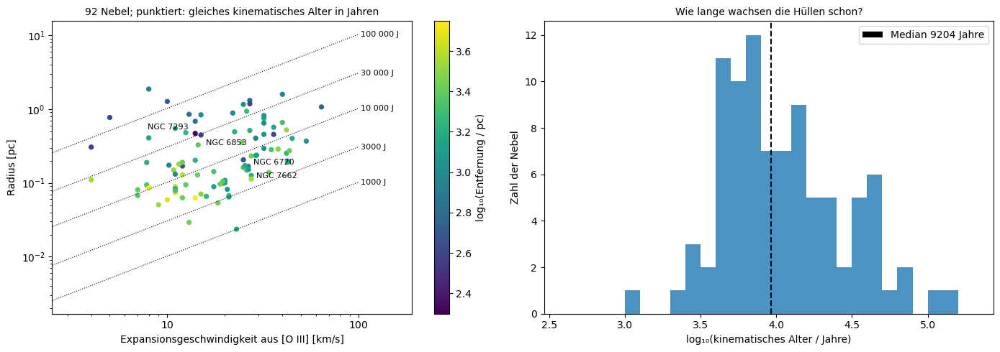

92 Nebel: Radius Median 0.192 pc (0.067 bis 0.846), Geschwindigkeit Median 19.8 km/s, Alter Median 9204 Jahre (10 % bis 90 %: 4369 bis 47055)
Rangkorrelation Radius–Geschwindigkeit: +0.37
                 d   pnRad   R_pc  ExpVel      t_kin
Name                                                
NGC 7662  1706.485   15.25  0.126    27.5   4485.705
NGC 6720   777.242   44.50  0.168    26.5   6186.738
NGC 6853   386.548  237.50  0.445    15.0  29011.293
NGC 7293   198.831  485.00  0.468    14.0  32650.414


In [33]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    planetary.distances()                   # Entfernungen aus Gaia
planetary.ages()

**29. Nebulae: Die Zanstra-Temperatur aus Wasserstoff**

Den heißen Stern sieht man im UV kaum, aber der Nebel zählt seine Photonen: Jedes Photon über 13.6 eV ionisiert ein Wasserstoffatom, und jede Rekombination liefert mit fester Wahrscheinlichkeit ein Hβ-Photon (Zanstra 1927). Das Verhältnis von Hβ-Fluss zur sichtbaren Helligkeit des Sterns steigt steil mit der Temperatur; für einen Schwarzkörper passt genau eine. Sterne, deren sichtbares Licht ein kühler Begleiter liefert, sind ausgelassen.

Hantel- und Helixnebel haben 127 000 und 116 000 K, NGC 3242 56 000 K und der Katzenaugennebel 45 000 K. Alle 77 Temperaturen aus Wasserstoff haben einen Median von 35 000 K, kühl für Sterne, die einen sichtbaren Nebel ionisieren: ein Hinweis, dass viele Nebel Photonen entweichen lassen.

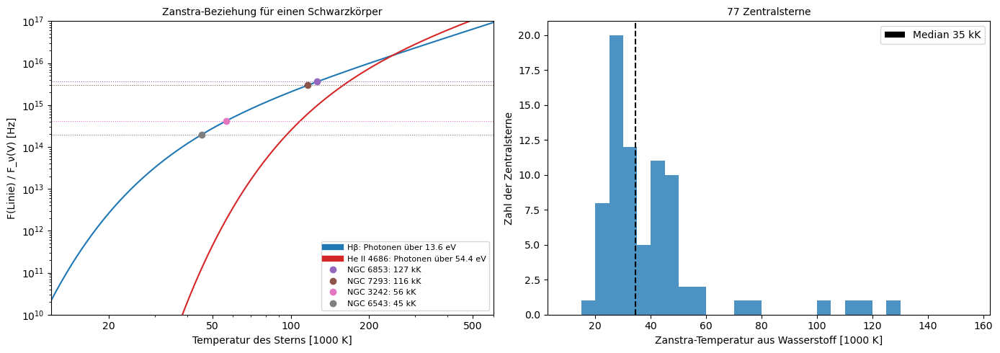

Zanstra-Temperatur (H) für 77 Sterne: Median 34507 K, 10 % bis 90 %: 24158 bis 53630 K
Ausgelassen wegen kühlem Begleiter: Me 1-1 (K1-2 II + ?), NGC 1514 (A0 + sdO), A 14 (A5 + ?), NGC 2346 (A5 IV + sdO), He 2- 36 (A2 III + sdO), SuWt 2 (A + A + ?)
          Vmag    EBV   V0     F_Hb      T_H
Name                                        
NGC 6853  13.9      0 13.9 3.47e-10 1.27e+05
NGC 7293  13.5      0 13.5 4.27e-10 1.16e+05
NGC 3242  12.3  0.209 11.7 3.25e-10 5.63e+04
NGC 6543  11.1 0.0233 11.1 2.65e-10 4.54e+04


In [34]:
planetary.zanstra_h()

**30. Nebulae: Ein zweites Thermometer – He II**

Dasselbe mit der Linie He II 4686, die die Photonen über 54.4 eV zählt. Ein großer, dünner Nebel lässt einen Teil der Photonen über 13.6 eV entweichen, dann wird die Wasserstoff-Temperatur zu niedrig; die selteneren Photonen über 54.4 eV werden meist vollständig geschluckt.

Für alle 39 Sterne liegt T(He II) über T(H), im Median 1.96-mal. Das Verhältnis wächst mit dem Radius des Nebels, von 1.64 unter 0.1 pc auf 2.21 darüber: Große, alte Nebel lassen mehr entweichen. Zusammen ergeben sich 39 Temperaturen mit He II (Median 70 000 K) und 38 aus Wasserstoff, die nur untere Grenzen sind.

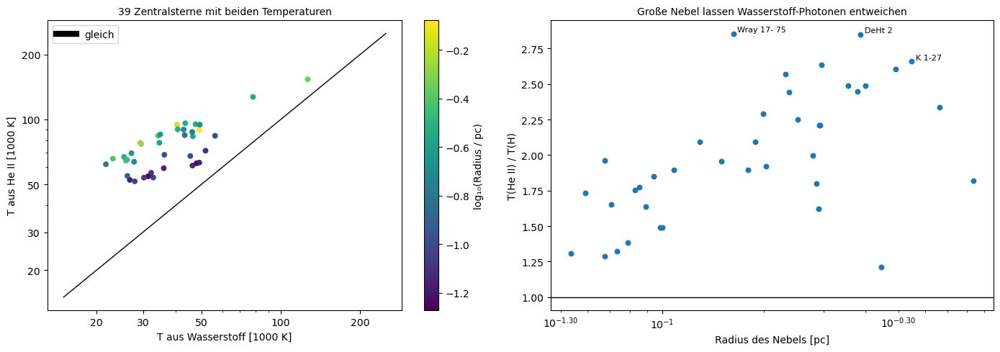

39 Sterne mit beiden Temperaturen: T(He II)/T(H) Median 1.96; Radius < 0.1 pc: 1.64 (12), ≥ 0.1 pc: 2.21 (27); Rangkorrelation mit dem Radius +0.61
Temperatur je Stern: 77 Sterne, davon 38 nur aus Wasserstoff (untere Grenze); Median mit He II 69719 K


In [35]:
planetary.zanstra_he()

**31. Nebulae: Krebsnebel – drei Fotos aus 60 Jahren**

Im Juli 1054 sahen Astronomen am chinesischen Kaiserhof einen „Gaststern“ im Stier, 23 Tage lang auch am Tag. An derselben Stelle steht heute der Krebsnebel, Messier 1, mit einem Pulsar in der Mitte, der sich 30-mal pro Sekunde dreht. Geladen werden zwei Palomar-Platten (1951 und 1991) und Pan-STARRS-Bilder (2009 bis 2014); gezeigt ist jedes Bild mit seiner Plattenlösung und seinem Datum, oben der ganze Ausschnitt von 12′, unten 80″ um ein helles Filament südlich des Pulsars.

Zwischen der ersten Platte (7. November 1951) und dem Pan-STARRS-Stapel (mittlere Epoche 2011.86) liegen 60.00 Jahre. 1951 ist das Innere des Nebels gesättigt und das Filament ein grober Streifen, 1991 ein klarer Strich, bei Pan-STARRS zerfällt es in Knoten. Wächst der Nebel seit 1054 gleichmäßig, wandert ein Filament 190″ vom Zentrum in 60 Jahren um etwa 12″, sieben Pixel der alten Platte.

Bild         Epoche   Pixel      Größe  Band und Belichtung
POSS-I E    1951.85   1.70″   424×424   103aE + rotes Plexiglas, 620–670 nm; Platte 070U, 50 min
POSS-II F   1991.80   1.01″   713×714   IIIaF + RG610, 610–690 nm; Platte A1YP, 65 min
PS1 r       2011.86   0.50″  1440×1440  CCD, Filter r, 550–690 nm; 16 Belichtungen, 720 s, 2009-12 bis 2014-03
PS1 i       2013.19   0.50″  1440×1440  CCD, Filter i, 690–820 nm; 22 Belichtungen, 990 s, 2010-11 bis 2014-12
PS1-Mosaik: Skycells im Überlapp angeglichen (Skala 1.003), Überlapp 17% des Ausschnitts
Zeitbasis 1951 -> PS1 r: 60.00 Jahre


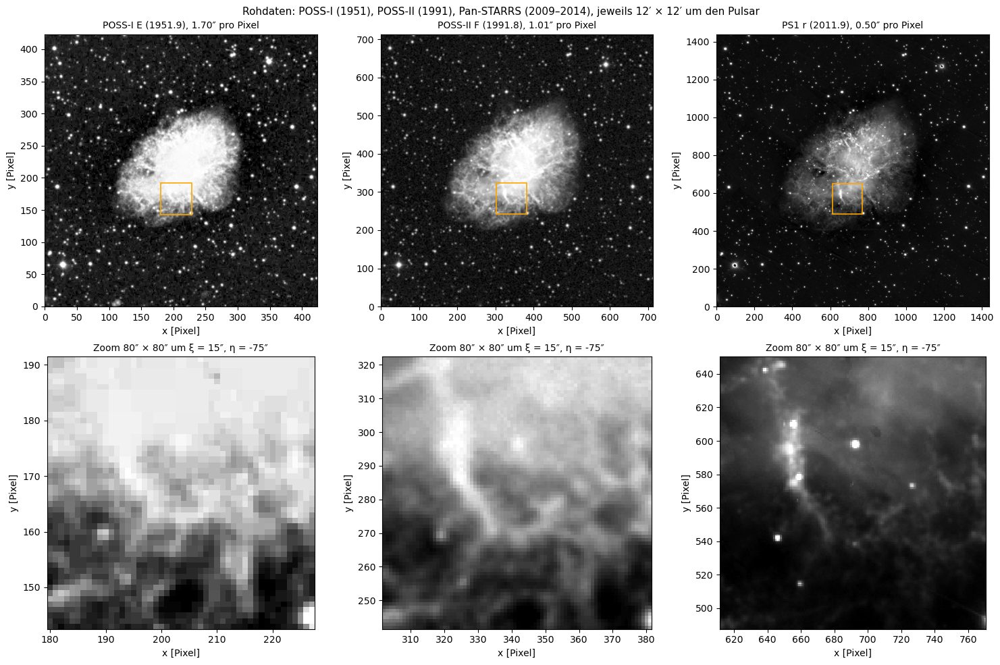

In [36]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    crab.load()                             # Platten, Pan-STARRS, Gaia und Pulsar laden
crab.photos()

**32. Nebulae: Filamente und Synchrotronlicht**

Der Filter i enthält keine helle Linie, dort leuchtet fast nur das Synchrotronlicht des Pulsarwindnebels. Im Filter r kommen Hα, [N II], [S II] und [O I] der Filamente dazu. Zieht man vom r-Bild das skalierte i-Bild ab, bleibt das Linienlicht.

Der Faktor 0.62 passt zu einem Synchrotronspektrum mit Rötung, das im Filter i heller ist. Das i-Bild zeigt eine glatte, wolkige Fläche, das Differenzbild nur das Netz der Filamente, dicht im Norden. Ein Drittel des r-Lichts kommt aus Linien. Dunkle Flecken am Pulsar sind vermutlich Strukturen, die sich mit halber Lichtgeschwindigkeit bewegen und zwischen den Belichtungen gewandert sind.

Synchrotron mit alpha = 0.6: r/i = 0.889 ohne Staub, 0.671 mit E(B-V) = 0.52
Synchrotron mit alpha = 0.8: r/i = 0.855 ohne Staub, 0.645 mit E(B-V) = 0.52
Synchrotron mit alpha = 1.0: r/i = 0.823 ohne Staub, 0.620 mit E(B-V) = 0.52
gemessen: k = 5. Perzentil von r/i im Inneren (ohne Sterne) = 0.618 -> Spektralindex alpha = 1.02 (mit Rötung); mit dem 10. Perzentil 0.643 -> alpha = 0.81
Anteil des Linienlichts am r-Licht des Feldes: 32%


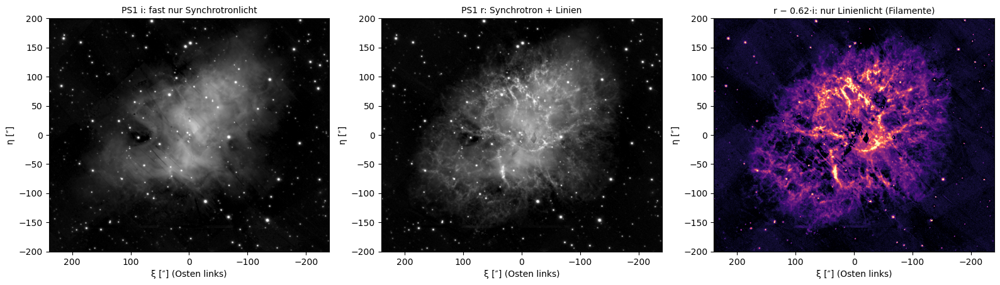

In [37]:
crab.filaments()

**33. Exoplanets: Die Datenbank NASA Exoplanet Archive – Kepler-Planeten mit dem tiefsten Transit**

Das NASA Exoplanet Archive am Caltech sammelt alle bestätigten Exoplaneten mit ihren Bahn- und Sterndaten; die Tabelle `pscomppars` stellt für jeden Planeten einen Satz von Werten aus verschiedenen Veröffentlichungen zusammen. Zieht ein Planet von der Erde aus gesehen vor seinem Stern vorbei, verdeckt er einen kleinen Teil der Sternscheibe, und der Stern wird für einige Stunden dunkler. Mit diesem Transit haben Kepler (2009 bis 2018) und TESS den größten Teil der bekannten Exoplaneten gefunden. Gezeigt werden die Kepler-Planeten um Sterne heller als Kepler-Magnitude 14 mit dem tiefsten Transit, gemessen oder, wo keine Messung vorliegt, aus (R_Planet / R_Stern)²; aus dieser Liste wählt man im nächsten Schritt einen Planeten.

Das Archiv kennt 6470 bestätigte Planeten, 4799 durch Transits gefunden und 2787 von Kepler. Von den 2763 Kepler-Planeten mit Transit stehen 943 um Sterne heller als Kp = 14. Alle 15 der Liste sind Gasriesen von 8 bis 20 Erdradien, sieben davon heiße Jupiter mit Perioden unter acht Tagen; am tiefsten ist der Transit von Kepler-468 b (2.35 %), einem Gasriesen auf einer Bahn von 38 Tagen. Kepler-8 b steht mit 0.91 % auf Platz 9. Kepler-16 b umkreist zwei Sterne; seine Tiefe ist aus den Radien berechnet.

In [38]:
MAX_KEPMAG = 14    # nur Sterne heller als Kepler-Magnitude 14 (gute Lichtkurven)
transits.top(MAX_KEPMAG)

Bestätigte Planeten im Archiv: 6470, davon 4799 durch Transits und 2787 von Kepler
Kepler-Planeten mit Transit: 2763, davon 943 um Sterne mit Kp < 14

Die 15 tiefsten Transits:
       Planet  Periode [d]  Radius [R⊕]  Tiefe [%]    Kp  entdeckt
 Kepler-468 b       38.479        13.34       2.35 13.78      2016
  Kepler-12 b        4.438        19.66       1.67 13.44      2011
  Kepler-16 b      228.776         8.45       1.42 11.76      2011
 Kepler-289 c      125.872        11.23       1.24 13.96      2014
  Kepler-15 b        4.943        10.76       1.13 13.76      2011
   Kepler-6 b        3.235        14.62       1.08 13.30      2009
 Kepler-422 b        7.891        12.89       1.06 13.44      2014
  Kepler-77 b        3.579        10.76       0.98 13.94      2013
   Kepler-8 b        3.522        15.87       0.91 13.56      2010
     KOI-12 b       17.855        13.79       0.91 11.35      2015
    KOI-351 h      331.603        11.25       0.83 13.80      2013
        PH2 b      

**34. Exoplanets: Einen Planeten wählen – Kepler-8 b im Katalog**

Hier wird der Planet für die folgenden Schritte gewählt, ein Name aus der Liste oben oder jeder andere Planet mit Kepler-Daten. Standard ist Kepler-8 b, ein aufgeblähter heißer Jupiter, also ein Gasriese auf einer Bahn von wenigen Tagen. Zuerst seine Werte aus `pscomppars`; das Quartal legt fest, welche drei Monate Kepler-Daten die nächsten Schritte nutzen.

Die Ausgabe gibt Periode 3.52250 Tage, Radius 15.87 Erdradien (etwa 1.4 Jupiterradien) um einen Stern mit 1.49 Sonnenradien und 6213 K und eine Transitdauer von 3.19 Stunden.

In [39]:
PLANET = "Kepler-8 b"      # ein Planet aus der Liste oben oder jeder andere mit Kepler-Daten
QUARTER = 1                # Kepler-Quartal (drei Monate) für Pixeldaten und Suche, Langzeitkadenz 29.4 min
k8 = transits.catalog(PLANET)

Planet:          Kepler-8 b  (Stern Kepler-8, T_eff = 6213 K)
Katalog-Periode: 3.52250 d
Katalog-Radius:  15.87 R_Erde  (Sternradius 1.49 R_Sonne)
Transitdauer:    3.19 h


**35. Exoplanets: Rohdaten – Pixelbild und Lichtkurve eines Quartals**

Das Target Pixel File enthält für jede Belichtung ein kleines Bild um den Stern. Die Pixel der Apertur (rot schraffiert), die die Kepler-Pipeline ausgewählt hat, werden addiert und ergeben die Rohlichtkurve. Die Zeit ist in BKJD angegeben, Tagen bezogen auf den Schwerpunkt des Sonnensystems.

Links das Pixelbild (logarithmisch): ein heller Kern über wenige Pixel, die Apertur umfasst sechs Pixel; 1626 Belichtungen von 6 × 6 Pixeln über 33.5 Tage. Rechts fällt der Fluss über das Quartal von etwa 35 500 auf 34 350 Elektronen pro Sekunde, um gut 3 %; das ist eine Drift des Teleskops, nicht des Sterns. Darunter liegen neun kurze Einbrüche von etwa 1 % alle 3.5 Tage: die Transits, schon in den Rohdaten sichtbar.

Kepler Quarter 01: 1626 Belichtungen, 6 x 6 Pixel, Dauer 33.5 Tage


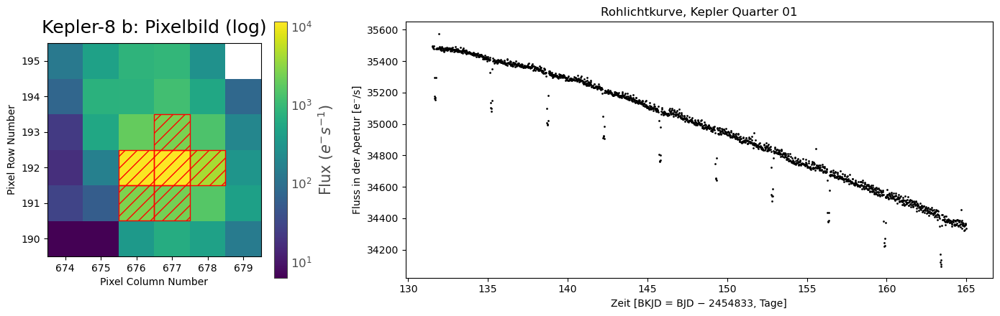

In [40]:
transits.raw(k8, QUARTER)

**36. Exoplanets: Normieren und Trend entfernen**

Die Lichtkurve wird auf 1 normiert, Ausreißer über 5 σ (etwa durch kosmische Teilchen) werden entfernt, und ein Savitzky-Golay-Filter schätzt den langsamen Trend, durch den geteilt wird. Das Filter passt in einem gleitenden Fenster ein Polynom an; das Fenster von 101 Belichtungen (etwa 50 Stunden) ist viel länger als ein Transit (3 Stunden) und kürzer als der Abstand der Transits.

Oben die Drift von etwa 1.014 auf 0.982, unten die Kurve ohne Trend: außerhalb der Transits flach bei 1 mit einer Streuung von einigen hundert ppm (Millionstel), die neun Transits fallen auf etwa 0.991. Sie bleiben gleich tief, weil das Fenster viel länger ist als ein Transit; nur am Ende des Quartals biegt die Kurve leicht ab, weil das Filter am Rand den Trend schlechter schätzt.

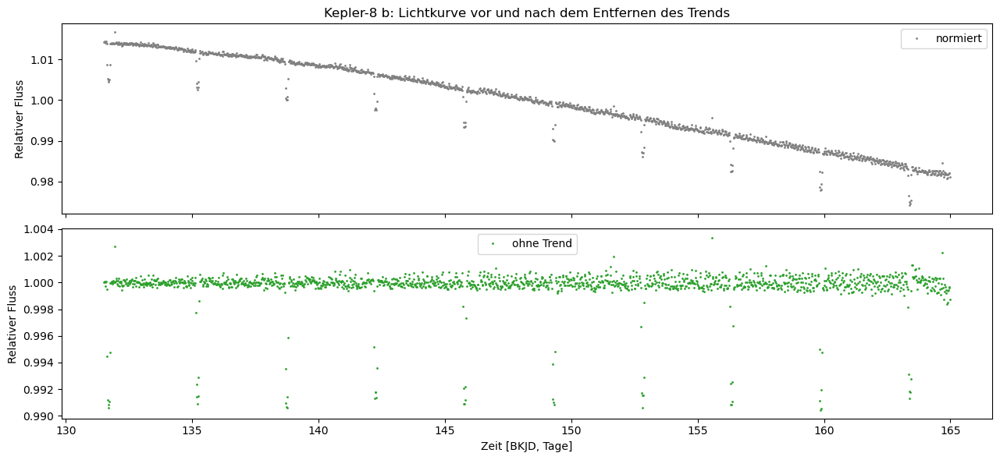

In [41]:
WINDOW = 101               # Fenster des Filters in Belichtungen (etwa 50 Stunden)
transits.detrend(k8, WINDOW)

**37. Exoplanets: Das BLS-Periodogramm**

Box Least Squares (BLS) probiert für jede Periode, jede Epoche und mehrere Dauern einen periodischen Kasten und misst, wie viel besser er die Daten erklärt als eine Konstante. Die Suche läuft grob über 0.5 bis 20 Tage und dann fein um den stärksten Peak. Nebenpeaks bei Bruchteilen oder Vielfachen der echten Periode heißen Aliase: Dort fällt ein Teil der Kästen ebenfalls auf Transits.

Der höchste Peak liegt bei 3.5224 Tagen, etwa doppelt so hoch wie alle übrigen; daneben die Aliase bei P/2 und P/3 und bei 2P, 3P, 4P. Die Periode 3.52235 d liegt nur 0.004 % neben dem Katalog, obwohl das Quartal nur neun Transits enthält. Der Kasten ist mit 2.69 Stunden kürzer als der Transit (3.19 h) und mit 7960 ppm flacher (Radiusverhältnis 0.089 statt 0.096): Er hat steile Wände und einen flachen Boden und mittelt über die schrägen Flanken.

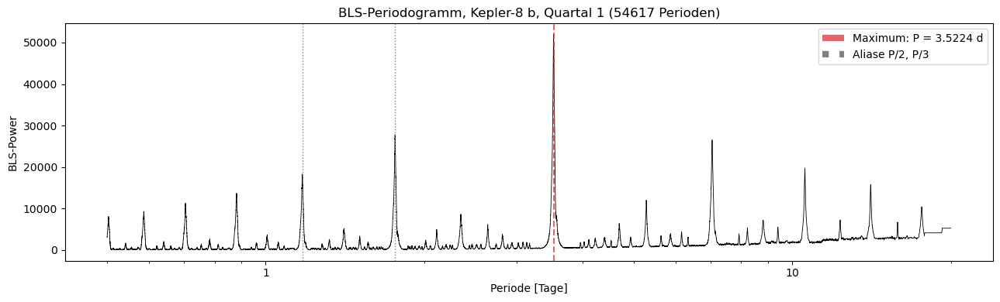

Periode:        3.52235 d   (Katalog 3.52250 d, Abweichung 0.004 %)
Transitmitte:   T0 = 131.6890 BKJD
Kastendauer:    2.69 h   (Katalog T14 = 3.19 h)
Kastentiefe:    7960 ppm  ->  Rp/R* = 0.0892   (Katalog 0.0958)


In [42]:
transits.periodogram(k8)

**38. Exoplanets: Gefaltete Lichtkurve**

Jede Belichtung bekommt die Zeit seit der nächsten Transitmitte; so liegen alle Transits des Quartals übereinander, und das Rauschen mittelt sich. Dazu kommen Mittelwerte in Intervallen von einem Achtel der Kastendauer.

Der Transit dauert etwa 3.5 Stunden, fällt in etwa einer Stunde auf 0.991 und hat einen leicht gekrümmten Boden, das Zeichen der Randverdunkelung: Der Rand der Sternscheibe ist dunkler als die Mitte. Mit 29.4 Minuten pro Belichtung liegen nur wenige Punkte auf Ein- und Austritt; für ein genaues Transitmodell bräuchte man Daten mit 1-Minuten-Kadenz.

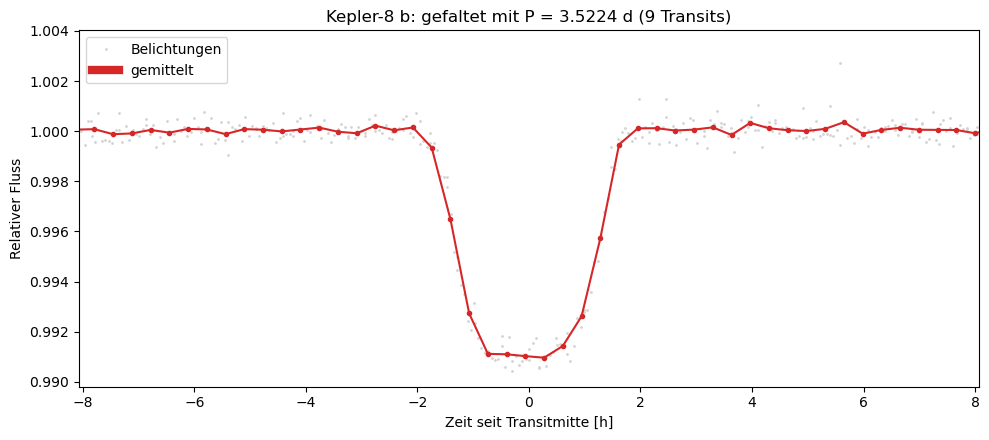

In [43]:
transits.fold(k8)

**39. Exoplanets: Vetting – Ephemeride, Pixeldaten und vier Jahre Lichtkurven**

Nicht jeder periodische Einbruch ist ein Planet. Ein erheblicher Teil der Kandidaten von Kepler und TESS sind Fehlalarme: zwei Sterne, die sich gegenseitig bedecken, oder ein schwacher Doppelstern im Hintergrund, dessen tiefer Einbruch durch das Licht des hellen Zielsterns verdünnt wird. Die Prüfung dagegen heißt Vetting. Geladen werden die Ephemeride des Archivs (Periode und Transitmitte, umgerechnet in Kepler-Zeit), die Pixel eines Quartals und alle 18 Quartale in Langzeitkadenz.

Die Ausgabe gibt P = 3.522499 Tage und die Transitmitte 121.11931 BKJD, dazu das Pixelbild von Quartal 1 mit 1626 Belichtungen von 6 × 6 Pixeln.

In [44]:
vet = vetting.load(PLANET, QUARTER)

Lade 18 Lichtkurven in Langzeitkadenz ...


Planet:        Kepler-8 b
Ephemeride:    P = 3.522499 d,  T0 = 2454954.11931 BJD = 121.11931 BKJD
Transitdauer:  3.19 h
Pixeldaten:    Kepler Quarter 01, 1626 Belichtungen, 6 x 6 Pixel


**40. Exoplanets: Differenzbild und Lichtschwerpunkt**

Liegt das fehlende Licht auf dem Zielstern? Für jeden Transit des Quartals entsteht ein Differenzbild aus dem Transitkern gegen die Messungen kurz davor und danach; so hebt sich die Drift heraus. Das Mittel über die Transits ist das Differenzbild, ihre Streuung der Fehler pro Pixel. Verglichen werden die Lichtschwerpunkte außerhalb des Transits und im Differenzbild; den Fehler ihres Abstands schätzt ein Bootstrap, der die Transits 500-mal neu zieht.

Die Ausgabe zählt 10 Transits mit 45 Belichtungen im Kern und 157 in der Grundlinie. Die Schwerpunkte liegen bei (2.755, 1.889) und (2.774, 1.899) Pixeln, 0.021 ± 0.019 Pixel oder 0.08 ± 0.08″ auseinander, verträglich mit null: Das fehlende Licht liegt auf dem Zielstern, auf einen kleinen Bruchteil eines Pixels von 3.97″ genau. Das größte SNR im Differenzbild ist 39.

In [45]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    vetting.ephemeris(vet)                  # Ephemeride verfeinern und Trend entfernen
vetting.centroid_test(vet)

10 Transits im Quartal: 45 Belichtungen im Transitkern, 157 in der Grundlinie; 1 Pixel ohne Daten
Schwerpunkt außerhalb des Transits: x = 2.755, y = 1.889 Pixel
Schwerpunkt des Differenzbilds:     x = 2.774, y = 1.899 Pixel
Abstand: 0.021 ± 0.019 Pixel = 0.08 ± 0.08"   (Pixelgröße 3.97")
Größtes SNR im Differenzbild: 39.0


**41. Exoplanets: Nachbarsterne aus Gaia DR3**

Gaia DR3 kennt Positionen und Helligkeiten fast aller Sterne bis zur 21. Größenklasse. Die Sterne um Kepler-8 werden auf das Pixelgitter eingetragen, und aus ihren Helligkeiten folgt der Anteil fremden Lichts in der Apertur. Die eigene Schätzung zählt nur Sterne, deren Mittelpunkt in einem Aperturpixel liegt; die Pipeline gibt mit CROWDSAP den Anteil des Zielsterns an und berücksichtigt dabei, wie sich das Licht eines Sterns über mehrere Pixel verteilt.

Links sitzt der Zielstern (rot) im hellsten Pixel; von drei schwachen Nachbarn liegt einer in der Apertur. In der Mitte konzentriert sich das fehlende Licht auf das Pixel des Zielsterns, rechts das SNR bis 39. Die Ausgabe zählt 4 Gaia-Sterne im Umkreis von 19″, 2 in der Apertur; der Nachbar mit G = 18.9 in 4.3″ Abstand trägt nach der eigenen Schätzung 0.71 % des Lichts bei, nach der Pipeline nur 0.05 %, weil nur ein Teil seines Lichts in der Apertur landet.

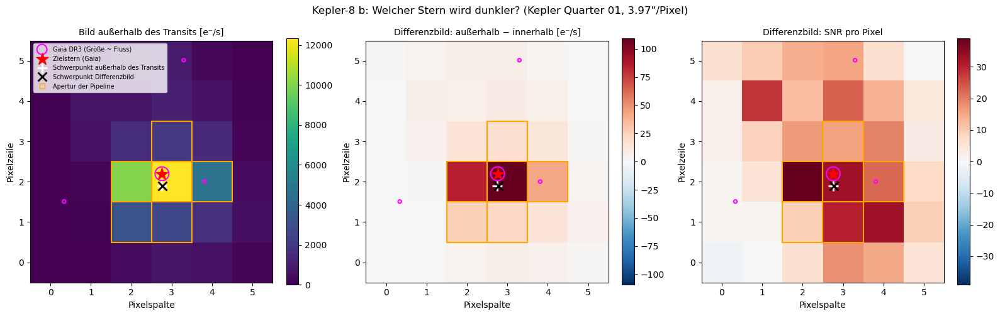

Gaia DR3: 4 Sterne im Umkreis von 19 arcsec, davon 2 in der Apertur
Fremdlicht in der Apertur, eigene Schätzung aus Gaia: 0.71 %
Fremdlicht in der Apertur, Pipeline (1 − CROWDSAP):   0.05 %


,Source,Gmag,sep_arcsec,in_aperture
0,2116730994965905280,13.52,0.07,True
3,2116730999263773824,18.89,4.27,True
2,2116730999261811456,20.50,9.97,False
1,2116730994966447360,18.40,11.46,False


In [46]:
vetting.neighbours(vet)

**42. Exoplanets: Populationen – alle bestätigten Planeten**

Mit über 6000 Planeten kann man ihre Verteilung untersuchen, so wie eine Volkszählung mehr zeigt als einzelne Lebensläufe. Am häufigsten sind Planeten, die es im Sonnensystem nicht gibt: zwischen Erde und Neptun groß, auf Bahnen enger als die des Merkur. Geladen wird die ganze Tabelle `pscomppars`; die Spalte `pl_bmassprov` sagt, ob eine Masse gemessen ist oder nur eine Untergrenze aus Radialgeschwindigkeiten.

Die Ausgabe zählt 6470 bestätigte Planeten. Fast alle haben einen Radius, aber nur 4491 einen mit Fehler; die übrigen Radien sind aus einer Masse-Radius-Beziehung geschätzt. Eine gemessene Masse haben 2495.

In [47]:
HIGHLIGHT = PLANET         # zur Orientierung markierter Planet
pops = populations.load(HIGHLIGHT)

6470 bestätigte Exoplaneten
  mit Radius:                  6420
  mit gemessenem Radiusfehler: 4491  (die übrigen Radien sind aus einer Masse-Radius-Beziehung geschätzt)
  mit gemessener Masse:        2495  (die übrigen: M sin i oder geschätzt)


**43. Exoplanets: Die Perioden-Radius-Ebene**

Gezeigt sind nur Planeten mit gemessenem Radius, gefärbt nach der Entdeckungsmethode. Geschätzte Radien würden als künstliches waagrechtes Band erscheinen.

Das Bild zeigt 4467 Planeten, fast alle durch Transits gefunden, weil nur ein Transit den Radius misst, und fast alle mit Perioden unter einigen hundert Tagen, weil weite Bahnen selten vor dem Stern vorbeiziehen. Oben links liegen die heißen Jupiter bei 10 bis 20 Erdradien und 1 bis 10 Tagen, mit Kepler-8 b (Stern); darunter ist die Neptun-Wüste fast leer, Planeten von Neptungröße auf Bahnen unter etwa 3 Tagen. Die meisten Planeten bilden das Band von 1 bis 4 Erdradien, im orange markierten Bereich der Radiuslücke sichtbar dünner.

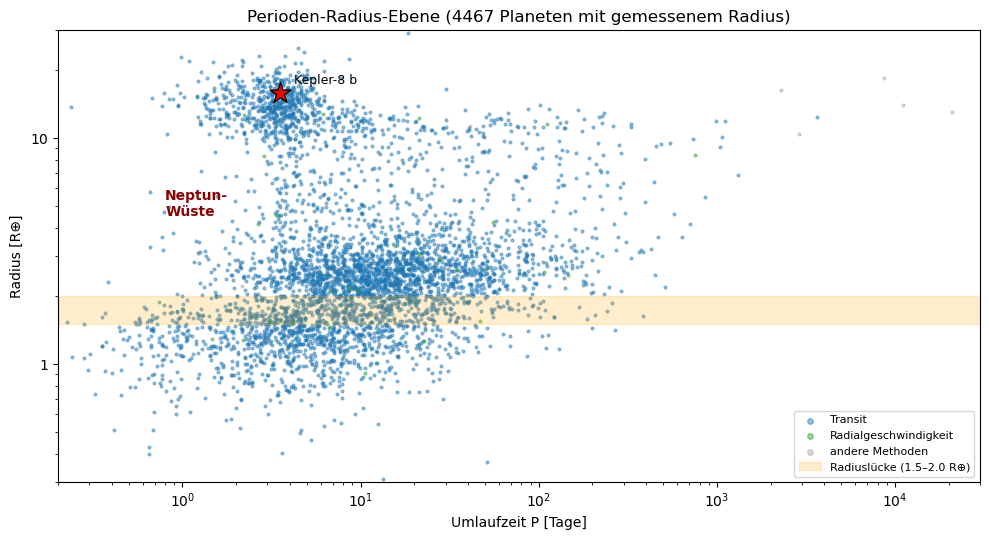

In [48]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    populations.quality(pops)               # Qualitätsfilter
populations.period_radius(pops)

**44. Exoplanets: Die Radiuslücke und das Masse-Radius-Diagramm**

Links glättet eine Kerndichteschätzung das Histogramm der Radien zu einer stetigen Kurve, in logarithmischen Radien. Das Tal ist ihr Minimum zwischen 1.3 und 2.5 Erdradien, die beiden Gruppen sind die Maxima links und rechts davon. Erklärt wird die Lücke mit Massenverlust: Kleine Planeten nahe am Stern verlieren ihre dünne Gashülle und bleiben als nackter Gesteinskern zurück. Rechts die Planeten mit gemessener Masse und gemessenem Radius, gefärbt nach der Einstrahlung in Einheiten der Einstrahlung der Erde, zusammen mit Erde, Neptun, Saturn und Jupiter.

Die Verteilung hat zwei Gipfel, die Supererden bei 1.52 und die Sub-Neptune bei 2.43 Erdradien, dazwischen das Tal bei 1.82, mitten im Bereich von Fulton et al. (2017). Das Tal ist flach, die Dichte fällt dort nur auf 80 % des kleineren Gipfels; die Radien im Archiv beruhen auf Sternradien aus vielen Quellen, und deren Streuung füllt die Lücke teilweise auf. Bis etwa 100 Erdmassen steigt der Radius steil mit der Masse: Gesteinsplaneten bei der Erde, darüber Sub-Neptune. Ab etwa einer Saturnmasse bleibt der Radius bei 10 bis 20 Erdradien, fast unabhängig von der Masse, weil Gasriesen vom Entartungsdruck getragen werden. Die größten Radien haben stark bestrahlte heiße Jupiter, die ihre Einstrahlung aufbläht; Kepler-8 b hat 188 Erdmassen und 15.9 Erdradien, eine mittlere Dichte von nur 0.26 g/cm³ (Saturn 0.69).

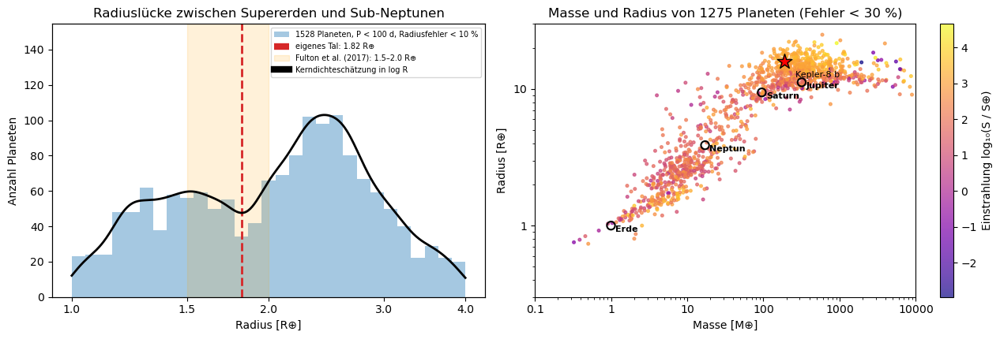

Tal (Minimum der KDE):          1.82 R_Erde
Maximum der Supererden:         1.52 R_Erde
Maximum der Sub-Neptune:        2.43 R_Erde
Tiefe des Tals: KDE im Tal / KDE im kleineren Maximum = 0.80
Kepler-8 b: M = 188 M⊕, R = 15.9 R⊕, mittlere Dichte 0.26 g/cm³ (Saturn 0.69, Jupiter 1.33)


In [49]:
populations.valley_and_mass(pops)

**45. Exoplanets: Atmosphären – Spektren von HATS-6 b im Archiv**

Während eines Transits fällt ein kleiner Teil des Sternlichts durch die Atmosphäre am Rand des Planeten, und die Moleküle darin hinterlassen ihre Absorptionsbanden: Bei diesen Wellenlängen wirkt der Planet größer, der Transit tiefer. Seit JWST lassen sich so Wasser, Methan und Kohlendioxid in Gasriesen nachweisen. Ziel ist HATS-6 b, ein warmer Gasriese um einen kleinen M-Zwerg, dessen Atmosphäre deshalb ein großes Signal gibt; das Spektrum stammt aus zwei Transits mit JWST NIRSpec PRISM (Guzmán Caloca et al. 2026).

Die Ausgabe listet drei Spektren derselben Veröffentlichung: die beiden Transits mit je 470 Punkten und das gemeinsame Spektrum mit 120 Punkten. Der Planet hat einen Jupiterradius, aber nur 0.32 Jupitermassen, umkreist seinen Stern in 3.33 Tagen und hat laut Katalog eine Gleichgewichtstemperatur von 713 K.

In [51]:
SPEC_PLANET = "HATS-6 b"   # ein Planet mit JWST-Spektrum im Archiv, z. B. auch "WASP-39 b"
T_RETRIEVED = 514          # K, Temperatur aus der Analyse von Guzmán Caloca et al. (2026); für andere Planeten None
atm = atmospheres.load(SPEC_PLANET, T_RETRIEVED)

3 Spektren von HATS-6 b im Archiv:


,spec_type,instrument,minwavelng,maxwavelng,num_datapoints,authors,bibcode,note
0,Transmission,Near Infrared Spectrograph (NIRSpec) - PRISM,0.5492,5.6377,470,Guzmán Caloca et al. 2026,2026AJ....172..193G,Visit 1; Eureka1 pipeline; Figure 2
1,Transmission,Near Infrared Spectrograph (NIRSpec) - PRISM,0.5547,5.6489,470,Guzmán Caloca et al. 2026,2026AJ....172..193G,Visit 2; Eureka1 pipeline; Figure 2
2,Transmission,Near Infrared Spectrograph (NIRSpec) - PRISM,0.6200,5.3800,120,Guzmán Caloca et al. 2026,2026AJ....172..193G,Co-added spectrum; Eureka1 pipeline; Figure 2


Planet: R = 1.00 R_Jup, M = 0.32 M_Jup, P = 3.33 d, T_eq (Katalog) = 713 K
Stern:  M1 V, T = 3724 K, R = 0.57 R_Sonne


**46. Exoplanets: Das Transmissionsspektrum**

Das gemeinsame Spektrum (schwarz) mit den einzelnen Transits (grau) und farbigen Streifen an den ungefähren Bandenmitten; eine Markierung ist noch kein Nachweis, weil Banden verschiedener Moleküle überlappen. Die rechte Achse rechnet die Tiefe in Skalenhöhen um, die natürliche Höheneinheit einer Atmosphäre: die Höhe, über die der Druck um den Faktor e fällt.

Unter 2 µm liegt das Spektrum nahe dem Median (32 917 ppm), zwischen 2.2 und 3.6 µm darüber, ein breiter Buckel mit dem Maximum bei 3.2 bis 3.3 µm, gut 3 Skalenhöhen hoch; dort überlappen Methan, Wasser und Ammoniak. Bei 4.3 µm (CO₂) folgt ein schmaler Anstieg. Bei 1.4 µm, wo Wasser ebenfalls eine Bande hat, ist nichts zu sehen, was zu Wolken oder Dunst passt. Eine Skalenhöhe ist 232 km bei 514 K, also 210 ppm: groß, weil der Stern klein und die Schwerkraft des Planeten mit 8.0 m/s² schwach ist.

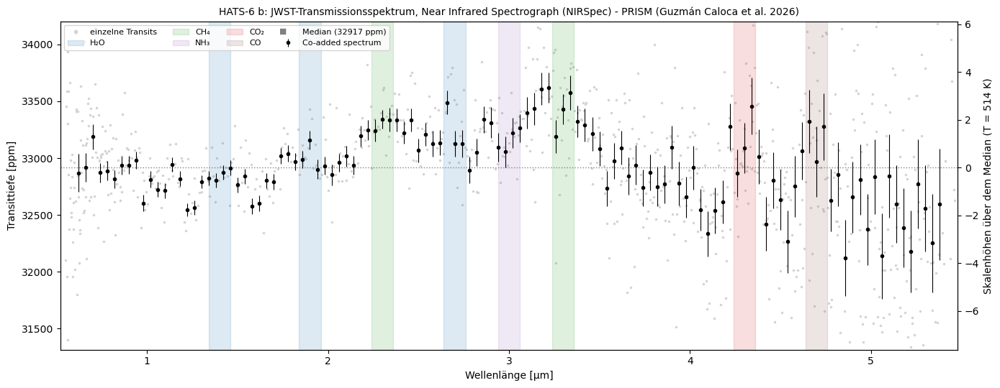

g = 8.0 m/s²
T = 713 K:  H = 321 km  ->  291 ppm pro Skalenhöhe
T = 514 K:  H = 232 km  ->  210 ppm pro Skalenhöhe


In [52]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    atmospheres.visits(atm)                 # Die beiden Transits vergleichen
atmospheres.spectrum(atm)

**47. Gravitational Waves: Die Datenbank GWOSC – alle Ereignisse**

Das Gravitational Wave Open Science Center (GWOSC) veröffentlicht die Messdaten von LIGO, Virgo und KAGRA und die Kataloge der Ereignisse. Seit 2015 haben LIGO, seit 2017 auch Virgo bei Pisa und zeitweise KAGRA in Japan einige hundert verschmelzende Paare aus schwarzen Löchern und Neutronensternen gemessen. Jedes Ereignis gibt Massen und Entfernungen, die kein Teleskop messen kann, weil diese Paare kaum Licht aussenden. Zusammen zeigen sie, wie schwer schwarze Löcher werden und ob es die vorhergesagten Massenlücken gibt, aber nur, wenn man weiß, wie stark die Empfindlichkeit der Detektoren das Bild verzerrt. Geladen wird der ganze öffentliche Katalog über die Event-API von GWOSC, alle Ereignisse mit allen Versionen.

Die Ausgabe zählt 671 Einträge zu 433 Ereignissen; viele stehen in mehreren Katalogen. Am meisten Einträge haben die O4-Kataloge GWTC-4.0, GWTC-4.1 und GWTC-5.0, dazu kommen marginale Kandidaten, vorläufige Listen und 42 Kandidaten einer unabhängigen Gruppe am Institute for Advanced Study (IAS).

In [53]:
gwtc.load()

671 Einträge, 433 verschiedene Ereignisse
katalog
GWTC-5.0               161
GWTC-4.1               140
GWTC-4.0               129
GWTC-2.1-confident      54
IAS-O3a                 42
GWTC-2                  39
GWTC-3-confident        35
GWTC-1-marginal         14
O1_O2-Preliminary       12
GWTC-1-confident        11
O4_Discovery_Papers      8
O3_Discovery_Papers      8
GWTC-3-marginal          7
O3_IMBH_marginal         5
GWTC-2.1-auxiliary       2
GWTC-2.1-marginal        2
Initial_LIGO_Virgo       2


**48. Gravitational Waves: Die lautesten und extremsten Ereignisse**

Die zehn Ereignisse mit dem größten Signal-Rausch-Verhältnis (SNR) aller Detektoren zusammen und die Extreme von Masse und Entfernung; aus diesem Katalog wählt man im nächsten Schritt ein Ereignis.

Am lautesten ist GW250114 (SNR 78.6): 34 und 32 Sonnenmassen in 405 Mpc, fast ein Zwilling von GW150914, aber mit den Detektoren von O4 gemessen. Das nächste Ereignis, GW170817 in 40 Mpc, steht nur auf Platz 7: Zwei Neutronensterne sind viel leichter und damit leiser. Das schwerste Paar ist GW231123 mit 137 und 101 Sonnenmassen, das fernste GW190403 bei z = 1.18; sein Signal ist mehr als halb so alt wie das Universum.

In [54]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    gwtc.selection()                        # Den Katalog bereinigen
gwtc.extremes()

Die zehn lautesten Ereignisse (Netzwerk-SNR):
           name             katalog   snr    m1    m2     dl    z
GW250114_082203            GWTC-5.0 78.60 33.76 32.26  405.0 0.09
GW250207_115645 O4_Discovery_Papers 68.91 35.20 30.60  187.0 0.04
GW230814_230901            GWTC-4.1 43.00 33.70 28.20  290.0 0.06
GW240920_124024            GWTC-5.0 37.40 37.10 31.90 1090.0 0.21
GW241011_233834            GWTC-5.0 35.80 19.50  5.96  212.0 0.05
GW231226_101520            GWTC-4.1 34.70 40.20 35.10 1180.0 0.23
       GW170817    GWTC-1-confident 33.00  1.46  1.27   40.0 0.01
GW241127_061008            GWTC-5.0 31.30 63.80 20.80 1080.0 0.21
GW240925_005809            GWTC-5.0 31.20  9.02  6.99  356.0 0.08
GW230627_015337            GWTC-4.1 28.70  8.40  5.74  305.0 0.07

Extreme:
  schwerstes (Gesamtmasse)  GW231123_135430    m1 =  137.0, m2 =  101.0 M☉, D_L =   2200 Mpc, z = 0.40
  leichtestes               GW190425           m1 =    2.1, m2 =    1.3 M☉, D_L =    150 Mpc, z = 0.03
  nächstes  

**49. Gravitational Waves: Ein Ereignis wählen – GW150914 und die Rohdaten von LIGO**

Hier wird das Ereignis für die folgenden Schritte gewählt, ein Name aus dem Katalog; Standard ist GW150914. Am 14. September 2015 maßen die beiden LIGO-Detektoren in Hanford (H1) und Livingston (L1) zum ersten Mal direkt eine Gravitationswelle, das Signal zweier verschmelzender schwarzer Löcher von je rund 30 Sonnenmassen. Die Welle änderte die 4 km langen Arme um etwa 4·10⁻¹⁸ m, weniger als ein Hundertstel eines Protonendurchmessers; 2017 gab es dafür den Nobelpreis. Geladen werden die Werte des Katalogs und 32 Sekunden um das Ereignis aus beiden Detektoren, 4096 Werte pro Sekunde, über die Bibliothek gwpy.

Der Katalog führt GW150914 in GWTC-2.1 als Paar schwarzer Löcher (BBH) aus der ersten Beobachtungskampagne O1: 34.6 und 30.0 Sonnenmassen im Ruhesystem der Quelle, Chirp-Masse 27.9, nach der Verschmelzung 61.5 Sonnenmassen; die fehlenden 3.1 Sonnenmassen hat die Welle als Energie abgestrahlt. Die Entfernung ist 470 Mpc (z = 0.10), das Signal-Rausch-Verhältnis beider Detektoren zusammen 26.0. Die GPS-Zeit 1126259462.4 (Sekunden seit dem 6. Januar 1980, ohne Schaltsekunden) ist der 14. September 2015, 09:50:45 UTC; geladen sind für beide Detektoren 32 s mit 4096 Hz.

In [55]:
EVENT = "GW150914"   # ein Ereignis aus dem Katalog oben, z. B. "GW250114" (das lauteste)
gwevent.load(EVENT)

Ereignis:    GW150914  (Katalog GWTC-2.1-confident, Kampagne O1, Typ BBH)
Zeit:        2015-09-14 09:50:45 UTC
Massen:      m1 = 34.6 M☉, m2 = 30.0 M☉ (im Ruhesystem der Quelle); Chirp-Masse 27.9 M☉, Endmasse 61.5 M☉
Entfernung:  D_L = 470 Mpc, z = 0.10
Signal:      Netzwerk-SNR 26.0
GPS-Zeit des Ereignisses: 1126259462.4


H1: 32 s, 4096 Hz


L1: 32 s, 4096 Hz


**50. Gravitational Waves: Rohdaten**

Der Strain, die relative Längenänderung ΔL/L, beider Detektoren über die ganzen 32 Sekunden, ohne jede Bearbeitung.

Die Ausschläge erreichen etwa ±0.5·10⁻¹⁸, das Signal hat nur etwa 10⁻²¹. Bei t = 0 ist deshalb nichts zu sehen: Das Rauschen ist mehrere hundertmal größer und besteht vor allem aus tiefen Frequenzen, den langsamen Wellen des Bodens. L1 liegt wegen solcher langsamen Schwankungen um etwa −1·10⁻¹⁸.

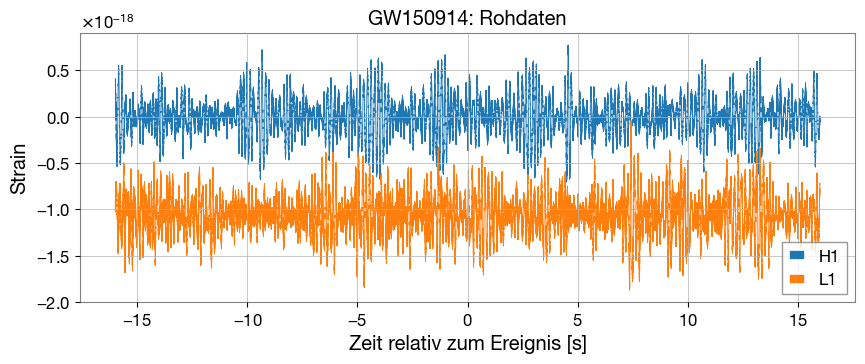

In [56]:
gwevent.raw_data()

**51. Gravitational Waves: Whitening und Bandpass**

Jede Frequenz wird durch ihr Rauschen geteilt (Whitening), danach bleiben nur 35 bis 350 Hz. L1 wird verschoben und, wenn nötig, mit −1 multipliziert: Ein echtes Signal muss beide Detektoren innerhalb der Lichtlaufzeit von 10 ms treffen, und L1 ist gegenüber H1 anders ausgerichtet. Verschiebung und Vorzeichen findet die Kreuzkorrelation beider Kurven innerhalb dieser 10 ms.

Bis etwa −0.05 s schwanken beide Kurven unabhängig um null. Danach schwingen sie im Gleichtakt, immer schneller und stärker, bis etwa 2.5 Rauscheinheiten kurz nach t = 0, dann bricht das Signal ab: Einspiralen, Verschmelzen, Ausschwingen des neuen schwarzen Lochs. Dass beide Kurven nach Verschiebung und Vorzeichenwechsel übereinanderliegen, ist der stärkste einfache Hinweis auf eine echte Welle. Die Kreuzkorrelation findet 7.3 ms und das Vorzeichen −1 (Korrelation −0.60), innerhalb der veröffentlichten 6.9 +0.5/−0.4 ms.

Kreuzkorrelation: L1 um +7.3 ms verschoben, Vorzeichen -1, Korrelation -0.60


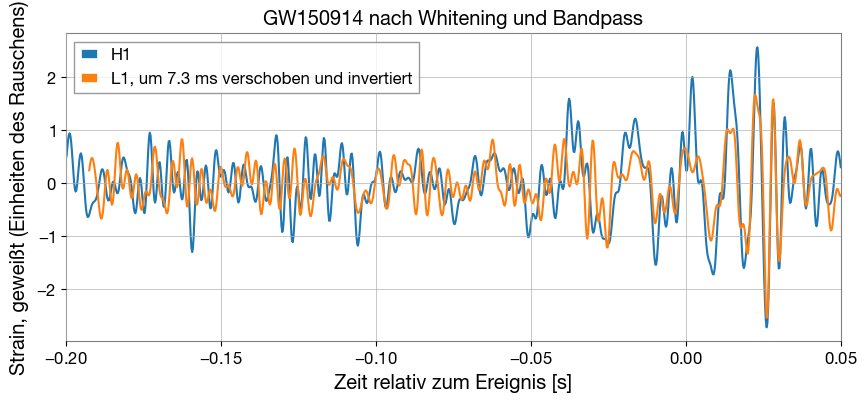

In [57]:
gwevent.whitened()

**52. Gravitational Waves: Zeit-Frequenz-Bild**

Die Q-Transformation zerlegt das Signal mit Wellenpaketen fester Schwingungszahl in Zeit und Frequenz, hier für 0.35 s um das Ereignis von 20 bis 500 Hz. Die Farbe ist die normierte Energie: im Rauschen um 1, beim Signal über 25.

Das Signal ist das gelbe, nach oben gekrümmte Band, der Chirp: Es beginnt bei etwa −0.08 s mit 35 Hz und steigt in rund 0.1 s auf über 250 Hz. Von 35 bis 150 Hz sind das etwa acht Schwingungen der Welle, also vier Umläufe des Paares. Aus der Krümmung des Bandes folgt die Chirp-Masse (m₁m₂)^(3/5)/(m₁+m₂)^(1/5), die Kombination der beiden Massen, die allein den Frequenzanstieg bestimmt.

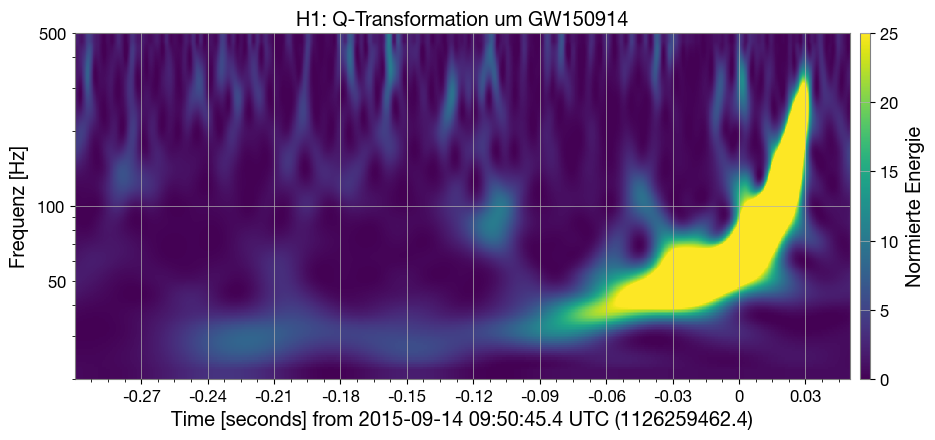

In [58]:
gwevent.spectrogram()

**53. Solar Astronomy: Zyklus – das Periodogramm der Sonnenfleckenzahl seit 1749**

Die Zahl der Sonnenflecken steigt und fällt mit etwa elf Jahren, und mit ihr fast alle Formen der Sonnenaktivität. SILSO (Royal Observatory of Belgium) liefert die Monatsmittel seit 1749, die längste fortlaufende Messreihe der Astronomie, und eine offizielle 13-Monats-Glättung, aus der die Minima der Zyklen folgen. Das Lomb-Scargle-Periodogramm passt für jede Periode zwischen 3 und 150 Jahren eine Sinusschwingung an die Monatsmittel an und misst, wie viel Varianz sie erklärt.

Der höchste Peak liegt bei 11.00 Jahren mit der Leistung 0.24: Ein einziger Sinus erklärt ein Viertel der Varianz. Seine Halbwertsbreite ist 0.65 Jahre, viel schmaler als die Spanne der einzelnen Zykluslängen von 9.0 bis 13.6 Jahren; das Periodogramm misst die mittlere Periode über 277 Jahre sehr genau, die verschiedenen Längen erscheinen als Nebenpeaks bei 10.0 und 11.8 Jahren. Der breite Buckel um 98 Jahre entspricht dem Gleissberg-Zyklus, aber die Reihe enthält davon nur 2.8 Perioden, zu wenig für einen sicheren Nachweis.

Höchster Peak: P = 11.00 Jahre, Leistung 0.24
Halbwertsbreite des Peaks: 0.65 Jahre; erwartet etwa P²/T = 0.44 Jahre
Mittlere Zykluslänge (aus den Minima): 11.03 Jahre, Streuung ± 1.18
Die sechs höchsten Peaks: 11.0 J (0.24), 10.0 J (0.11), 11.8 J (0.08), 97.8 J (0.07), 8.5 J (0.03), 66.8 J (0.03)


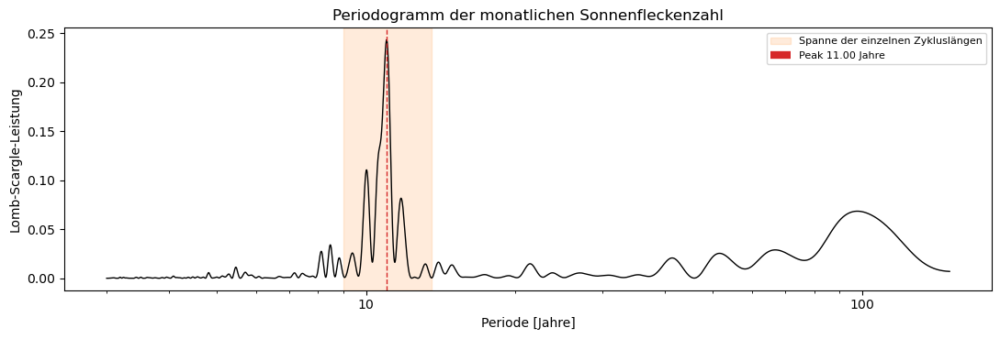

In [59]:
REFRESH = False                # True: Reihen neu von SILSO laden (SILSO ergänzt jeden Monat den Vormonat)
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    cycle = sunspots.load(REFRESH)          # Monatsmittel und Glättung von SILSO
    sunspots.smoothing(cycle)               # Die 13-Monats-Glättung
    sunspots.extrema(cycle)                 # Minima, Maxima und Zykluslängen
sunspots.periodogram(cycle)

**54. Solar Astronomy: Flares – zwei Listen der GOES-Satelliten**

Ein Flare setzt über einer Fleckengruppe in wenigen Minuten bis zu 10²⁵ J frei. Sein Röntgenlicht erreicht die Erde nach acht Minuten, ionisiert die obere Atmosphäre und unterbricht den Kurzwellenfunk. Seit 1975 messen die geostationären GOES-Satelliten der NOAA den Röntgenfluss der ganzen Sonne; die Klasse eines Flares (A, B, C, M, X, je zehnmal stärker) folgt aus dem Spitzenfluss. Geladen werden die Flare-Listen von GOES-16 und GOES-18 in wissenschaftlicher Qualität und die Sonnenfleckenzahl.

GOES-16 hat von Februar 2017 bis April 2025 16 085 Flares, GOES-18 von Juni 2022 bis Oktober 2026 13 660. Fast alle sind Klasse B oder C; GOES-16 hat mehr B-Flares (4780 gegen 942), weil es die ruhigen Jahre 2018 bis 2020 sah, als der Hintergrund niedrig war.

In [60]:
EVENT_DAY = "2024-10-03"       # Tag des X-Flares für die Lichtkurve (Schritt 56)
fla = flares.load(EVENT_DAY, REFRESH)

GOES-16: 2017-02-09 bis 2025-04-06, 16085 Flares  A: 2  B: 4780  C: 9612  M: 1609  X: 82   (Datei sci_xrsf-l2-flsum_g16_s20170209_e20250406_v2-2-1.nc)
GOES-18: 2022-06-17 bis 2026-10-11, 13660 Flares  A: 0  B: 942  C: 10806  M: 1819  X: 93   (Datei sci_xrsf-l2-flsum_g18_s20220617_e20261011_v2-2-1.nc)


**55. Solar Astronomy: Flare-Rate und Sonnenfleckenzahl**

Für jeden vollständigen Monat werden die Flares ab C1, ab M1 und ab X1 gezählt und mit der Sonnenfleckenzahl R verglichen; für die M-Flares mit einer Poisson-Regression N = k·R^β.

Alle Raten folgen dem Zyklus: fast keine Flares im Minimum 2018 bis 2020, die meisten 2024. Die Rangkorrelation ist 0.93 für C-, 0.90 für M- und nur 0.61 für X-Flares, die selten sind und in Schüben kommen. Die M-Flares wachsen wie R^1.77: doppelt so viele Flecken, mehr als dreimal so viele M-Flares. Die Monatszahlen schwanken aber 32-mal so stark wie bei einem Poisson-Prozess. 2019 gab es bei R = 4 nur 3 M-Flares, 2024 bei R = 155 864 M- und 50 X-Flares.

108 Monate von 2017-03 bis 2026-09
≥C1 gegen Sonnenfleckenzahl: Spearman ρ = 0.93
≥M1 gegen Sonnenfleckenzahl: Spearman ρ = 0.90
≥X1 gegen Sonnenfleckenzahl: Spearman ρ = 0.61
M-Flares pro Monat = 0.0075 · R^1.77 (± 0.01 unter Poisson-Annahme)
χ²/dof = 31.6: die Varianz ist 32-mal so groß wie bei Poisson; realistischer Fehler von β ≈ ± 0.04

Flares pro Jahr:
t_peak   2017  2018  2019  2020   2021    2022    2023    2024    2025    2026
C       413.0  33.0  64.0  83.0  443.0  2192.0  2845.0  2794.0  2654.0  1566.0
M        53.0   1.0   3.0   2.0   29.0   193.0   351.0   864.0   332.0   213.0
X         6.0   0.0   0.0   0.0    1.0     7.0    13.0    50.0    18.0    13.0
SN       22.0   7.0   4.0   9.0   29.0    83.0   125.0   155.0   123.0    85.0


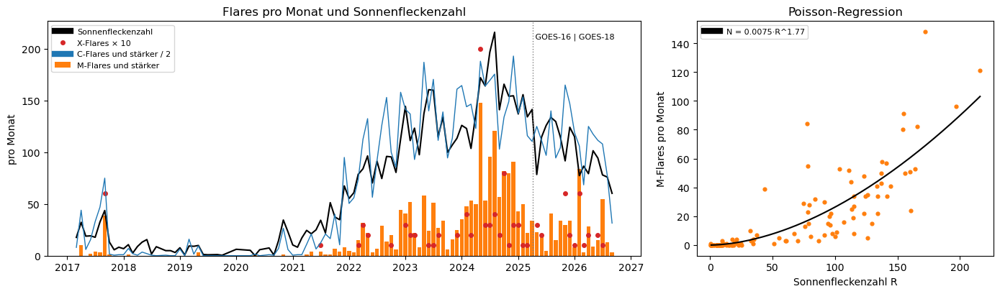

In [61]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    flares.classes(fla)                     # Aus Ereignissen werden Flares
flares.rate(fla)

**56. Solar Astronomy: Die Lichtkurve des X-Flares vom 3. Oktober 2024**

Die 1-Minuten-Werte von GOES-18 zwischen 11:30 und 14:00 UT, beide Kanäle. An die erste Stunde nach dem Maximum wird ein exponentielles Abklingen angepasst. Das Verhältnis der beiden Kanäle (härteres zu weicherem Röntgenlicht) zeigt die Temperatur.

Ab 12:13 UT steigt der Fluss in fünf Minuten um zwei Größenordnungen auf X8.8 (8.806·10⁻⁴ W/m² um 12:18 UT, genau wie in der Liste) und fällt dann mit τ = 7.6 ± 0.1 Minuten ab; die Kurve passt auf 5 %. Die halbe Höhe kommt aber erst nach 8 statt 5.2 Minuten, weil direkt nach dem Maximum noch geheizt wird. Das Härteverhältnis erreicht sein Maximum um 12:16, zwei Minuten vor dem Fluss: Das Plasma ist zuerst am heißesten und erst danach am dichtesten.

Eigenes Maximum: 12:18 UT, F = 8.806e-04 W/m² → X8.8
Flare-Liste GOES-18: Start 12:08, Maximum 12:18, Ende 12:26, Klasse X8.8, Hintergrund 9.2e-06
Abklingzeit τ = 7.6 ± 0.1 min, Hintergrund danach 1.4e-05 W/m², relative Abweichung 5.0%
Halbe Höhe: nach Modell τ·ln2 = 5.2 min, gemessen 8 min (Liste: Ende nach 8 min)
Härteverhältnis A/B: Maximum 0.42 um 12:16, am Flare-Maximum 0.38
Steilster Anstieg von XRS-B um 12:17, 1 min vor dem Maximum


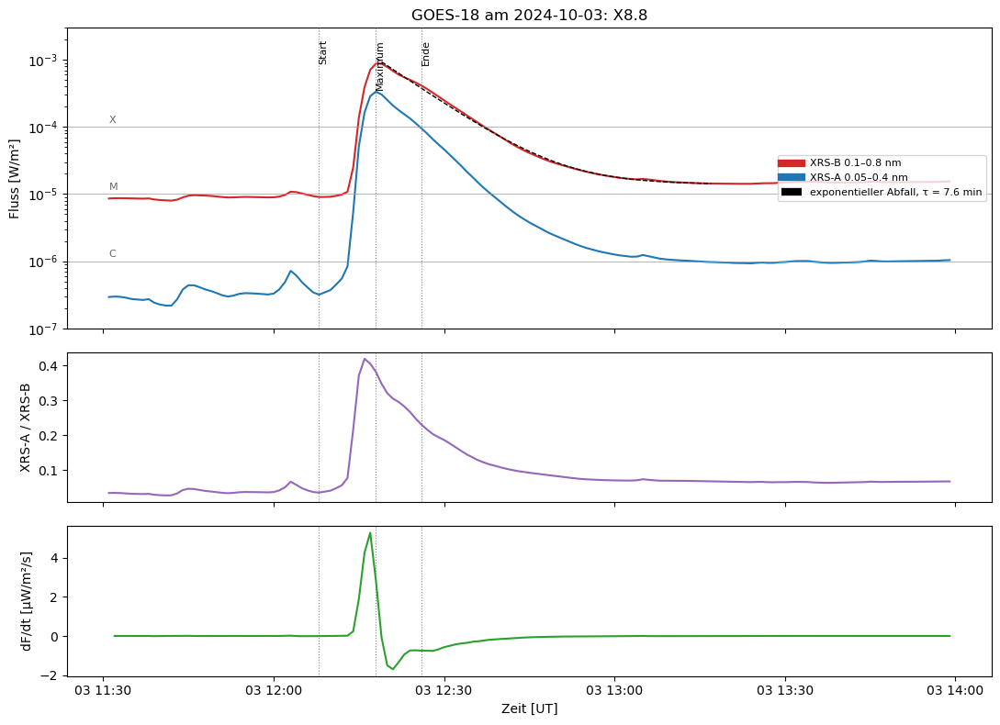

In [62]:
flares.lightcurve(fla)

**57. Solar Astronomy: Orte – Tagesberichte des Space Weather Prediction Center**

Flares entstehen über aktiven Regionen, Fleckengruppen mit starkem Magnetfeld. Das Space Weather Prediction Center der NOAA veröffentlicht täglich zwei Listen: die Ereignisse des Tages, darunter Röntgenflares mit ihrer Region, und die Solar Region Summary (SRS) mit Position, Fläche und magnetischer Klasse jeder Region um 00 UT. Geladen werden beide für jeden Tag von 2024.

Für 2024 sind alle 366 Ereignislisten und 365 SRS im Archiv, mit 3766 Röntgenflares, 3801 Hα-Beobachtungen und 3102 Regionstagen von 412 Regionen.

In [63]:
YEAR = 2024                    # Jahr für die Flare-Positionen
pos = positions.load(YEAR)

2024: 366 Ereignislisten, 365 SRS (von 366 Tagen)
Ereignisse nach Typ: {'RSP': 4355, 'FLA': 3801, 'XRA': 3766, 'RBR': 3766, 'DSF': 95, 'RNS': 76}
SRS 2024: 3102 Regionstage, 412 Regionen


**58. Solar Astronomy: Die Position jedes Flares**

Zu jedem Flare wird seine Region in der SRS desselben Tages gesucht und ihre Länge mit der differentiellen Rotation auf die Zeit des Maximums gedreht: Die Sonne dreht sich am Äquator in etwa 25 Tagen, an den Polen langsamer. Mit der Neigung der Sonnenachse und dem scheinbaren Sonnenradius zur Flarezeit folgen die Bildkoordinaten.

89.7 % der Flares bekommen eine Position. 118 liegen danach hinter dem Rand, 115 davon am Westrand: Die Region war schon verschwunden, die hohen Schleifen darüber noch sichtbar. Auf der Scheibe liegen die Flares auf waagrechten Spuren, Regionen, die mit der Rotation über die Scheibe wandern, in zwei Bändern nördlich und südlich des Äquators. Der stärkste Flare zeigt die Drehung: Seine Region stand um 00 UT bei S15E06 und hatte sich bis 12:18 UT um 6.9° auf S15W01 gedreht.

quelle
SRS desselben Tages        3095
keine Region                325
SRS des Folgetags           259
Region nicht in der SRS      63
SRS des Vortags              24



Position bestimmt für 89.7% der Flares; davon hinter dem Rand (z < 0): 118, davon 115 am Westrand (Region schon hinter dem Rand, Flare noch sichtbar)
Stärkster Flare X9.0 am 2024-10-03 12:18 in NOAA 13842: SRS S15E06 um 00 UT → gedreht S15W01 (+6.9°), Tx = 15″, Ty = -353″


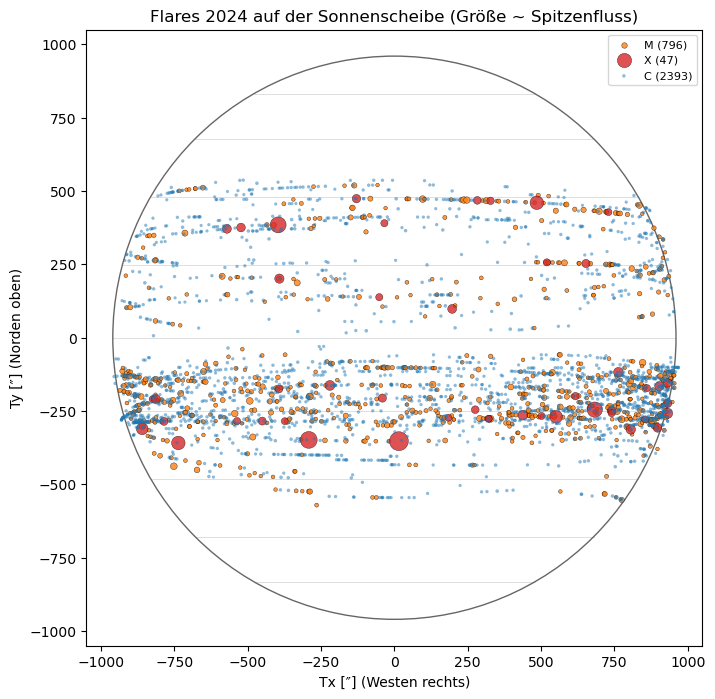

In [64]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    positions.xray(pos)                     # Röntgenflares und Regionen
positions.locate(pos)

**59. Solar Astronomy: Bild – der X-Flare im Blick von SDO**

Das Solar Dynamics Observatory der NASA beobachtet die Sonne seit 2010 ohne Pause, alle 12 Sekunden in zehn Wellenlängen (AIA), und misst das Magnetfeld an der Oberfläche (HMI). Geladen werden je ein Bild in 131, 171, 304 und 1600 Å und ein Magnetogramm im Maximum des X-Flares vom 3. Oktober 2024 in NOAA 13842, nahe der Scheibenmitte.

Die fünf Bilder stammen von 12:18:08 bis 12:18:30 UT. Bei einem Flare verkürzt AIA die Belichtung: in 131 Å auf 0.015 s, in 304 Å auf 0.42 s, dort ist kein Pixel gesättigt; 171 Å lief mit 2.0 s und hat 8647 gesättigte Pixel. Die Sonne erschien mit 959.1″ Radius, und ihr Nordpol war um 6.58° zur Erde geneigt.

In [65]:
PEAK = "2024-10-03T12:18:00"   # Maximum des Flares laut GOES (UT)
BOX = 200                       # Größe des Ausschnitts um die aktive Region [Bogensekunden]
img = sdo.load(PEAK, BOX)

Kanal Zeit (UT)               Belichtung    Pixel   Maximum  gesättigt
131   2024-10-03T12:18:10       0.0145 s   0.601″      4625          0
171   2024-10-03T12:18:09       1.9996 s   0.599″     16375       8647
304   2024-10-03T12:18:08       0.4158 s   0.600″     11779          0
1600  2024-10-03T12:18:14       2.9013 s   0.609″     16375         73
HMI   2024-10-03T12:18:30           45 s   0.504″      4993          -

Abstand SDO-Sonne 1.0005 AU, Sonnenradius 959.1 arcsec, B0 = 6.58 deg


**60. Solar Astronomy: Die ganze Sonne in fünf Kanälen**

Jedes Bild wird auf 4 × 4 Pixel gemittelt, durch die Belichtungszeit geteilt und logarithmisch gezeigt; jeder AIA-Kanal sieht Plasma einer anderen Temperatur.

In 131 Å (heißes Plasma, etwa 10 Millionen Kelvin) ist die ruhige Sonne fast dunkel und der Flare das einzige auffällige Objekt. In 171 Å sieht man die ganze Korona mit ihren Schleifen, der Flare ist dort ein gesättigter Fleck mit Streifen. In 304 und 1600 Å leuchten der Flare und die hellen Gebiete der aktiven Regionen. Das Magnetogramm zeigt die Regionen als schwarz-weiße Paare entgegengesetzter Polarität, die meisten in einem Band südlich des Äquators.

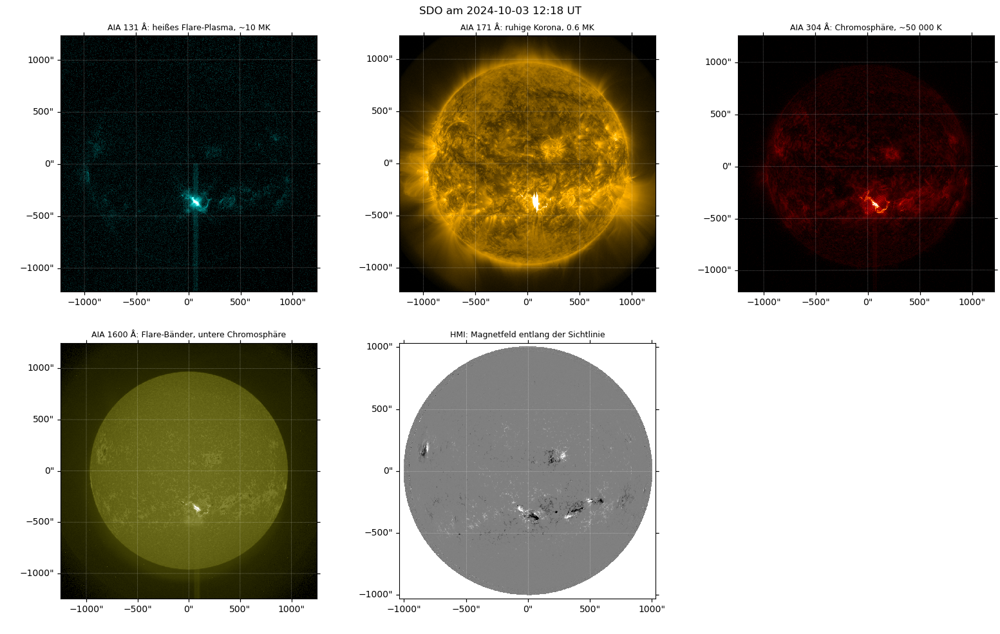

In [66]:
sdo.overview(img)

**61. Cosmology: Pantheon+ – die Supernovae des Hubble-Diagramms**

1929 fand Edwin Hubble, dass sich Galaxien umso schneller entfernen, je weiter sie weg sind; die Steigung, die Hubble-Konstante H₀, misst, wie schnell sich das Universum heute ausdehnt. Supernovae vom Typ Ia, Explosionen Weißer Zwerge mit fast gleicher Leuchtkraft, machen daraus seit 1998 ein Präzisionswerkzeug, mit dem auch die beschleunigte Expansion entdeckt wurde. Geladen wird Pantheon+: 1701 Lichtkurven von 1543 Supernovae bis z = 2.26, mit der vollen Kovarianzmatrix und den Entfernungen der Kalibratoren aus Cepheiden (SH0ES).

Die Ausgabe zählt die Lichtkurven, die Kalibratoren mit Cepheiden-Entfernung und die Größe der Kovarianzmatrix (1701 × 1701), die gemeinsame Fehler aller Lichtkurven enthält.

In [67]:
hubble.load()

1701 Lichtkurven von 1543 Supernovae aus 20 Durchmusterungen; z von 0.0012 bis 2.26
Kalibratoren: 77 Lichtkurven von 43 Supernovae; Hubble-Fluss (SH0ES): 277 Lichtkurven, z = 0.0234 bis 0.1490
Kovarianz: (1701, 1701), größte Asymmetrie vor dem Symmetrisieren 3e-08 mag², kleinster Eigenwert 8.03e-04
Test: μ(z = 0.1, H₀ = 70, Ω_m = 0.3) = 38.315 | leeres Universum: 38.265


**62. Cosmology: Der Katalog**

Die Rotverschiebungen, getrennt nach Kalibratoren, dem Hubble-Fluss von SH0ES und dem Rest, und die Lage am Himmel.

77 Lichtkurven gehören zu Kalibratoren (z bis 0.017), 277 zum Hubble-Fluss (z = 0.023 bis 0.15). Das größte Maximum liegt bei z ≈ 0.3: Tiefe Durchmusterungen finden auf kleiner Fläche viele ferne Supernovae, nahe muss man über den ganzen Himmel suchen. 98 Supernovae haben zwei Lichtkurven, 29 drei oder mehr, weil mehrere Durchmusterungen dieselbe Explosion sahen.

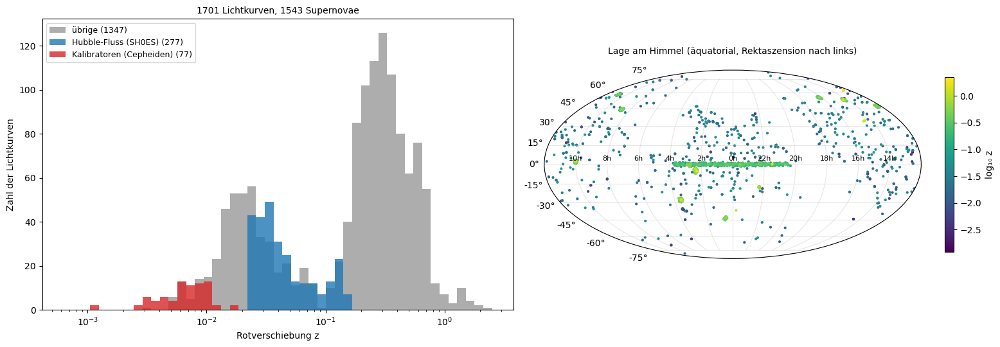

Lichtkurven pro Supernova: 1 bei 1416, 2 bei 98, 3 oder mehr bei 29
Median z: alle 0.164, z < 0.1: 44%, z > 1: 25 Lichtkurven
Kalibratoren: 1981B, 1990N, 1994ae, 1995al, 1997bp, 1997bq, 1998aq, 1998dh, 1999cp, 1999dq, 2001bg, 2001el ...


In [68]:
hubble.catalog()

**63. Cosmology: Das kosmische Netz entsteht – eine eigene N-Körper-Simulation**

Kurz nach dem Urknall schwankte die Dichte nur um 10⁻⁵; die Gravitation hat diese Schwankungen verstärkt, bis das heutige Netz aus Haufen, Filamenten und Leeren entstand. Auf kleinen Skalen hilft nur eine Simulation: Eine Particle-Mesh-Simulation verteilt die Dunkle Materie auf 256³ Teilchen in einem Würfel von 250 Mpc/h und rechnet ihre Bewegung unter der gemeinsamen Gravitation im expandierenden Universum, mit den Parametern von Planck 2018 (46 Zeitschritte in etwa 30 s, die Teilchenschleifen sind mit numba kompiliert). Gezeigt ist eine Scheibe von 20 Mpc/h Dicke bei z = 3, 1 und 0.

Bei z = 3 ist das Netz schon angelegt, aber kontrastarm; bis heute leeren sich die Gebiete dazwischen, und die Materie sammelt sich in Filamenten und Haufen. Der Anteil des Volumens mit weniger als halber mittlerer Dichte wächst von 29 % auf 68 %, enthält aber nur 10 % der Masse; 40 % der Masse stecken in 1.3 % des Volumens.

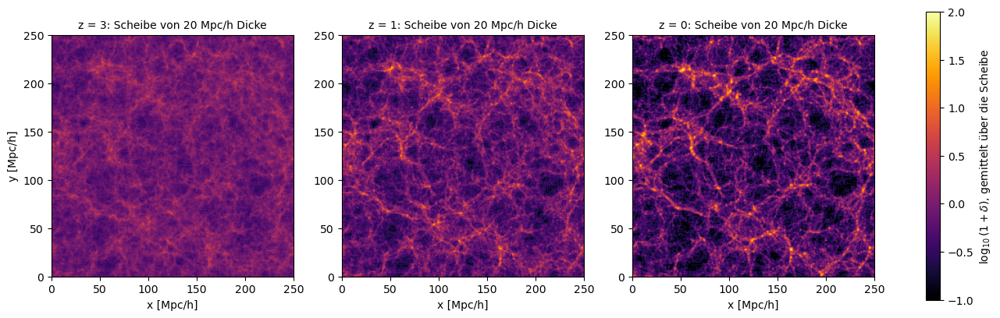

z = 3: δ > 9 in 0.17% des Volumens mit 2.5% der Masse; δ < −0.5 in 29.2% des Volumens mit 9.5% der Masse; dichteste Zelle δ = 145
z = 1: δ > 9 in 0.97% des Volumens mit 20.4% der Masse; δ < −0.5 in 54.2% des Volumens mit 11.6% der Masse; dichteste Zelle δ = 618
z = 0: δ > 9 in 1.33% des Volumens mit 39.6% der Masse; δ < −0.5 in 68.1% des Volumens mit 9.9% der Masse; dichteste Zelle δ = 1833


In [69]:
with prereq.silent():                       # Vorstufen ohne Ausgabe, deren Ergebnisse dieser Schritt braucht
    nbody.load(big=False)                   # Die Simulation rechnen (nur der kleine Würfel)
nbody.cosmic_web()

**64. Cosmology: Die akustischen Peaks der Hintergrundstrahlung**

Etwa 380 000 Jahre nach dem Urknall verbanden sich Elektronen und Protonen zu Wasserstoff, und das Licht lief seitdem frei; es erreicht uns, um den Faktor 1090 gedehnt, als Mikrowellenstrahlung von 2.7255 K. Ihre Temperatur schwankt um etwa 100 μK, ein Abbild der Dichteschwankungen von damals. Schallwellen im Plasma haben diesen Flecken bevorzugte Größen gegeben, die akustischen Peaks im Leistungsspektrum. Geladen werden das Spektrum von Planck 2018 mit dem besten Modell und vier Felder von 20° × 20° aus den Planck-Karten bei 100 und 143 GHz, fern der Milchstraße.

Das Spektrum reicht von ℓ = 2 bis 2508. Die vier Felder schwanken um 96 bis 113 μK; einige Lücken in den Karten sind gefüllt.

In [70]:
cmbpeaks.load()

Spektrum: ℓ = 2 bis 2508 (2507 Werte), 83 Bins, bestes Modell bis ℓ = 2508
Nordpol         (l, b) = (0, 90): 400×400 Pixel, Streuung 100 GHz 101.0 μK, 143 GHz 101.8 μK, gefüllte Lücken 384
Südpol          (l, b) = (0, -90): 400×400 Pixel, Streuung 100 GHz 100.8 μK, 143 GHz 101.6 μK, gefüllte Lücken 114
Nord, l = 150°  (l, b) = (150, 62): 400×400 Pixel, Streuung 100 GHz  96.3 μK, 143 GHz  97.6 μK, gefüllte Lücken 0
Süd, l = 210°   (l, b) = (210, -62): 400×400 Pixel, Streuung 100 GHz 112.9 μK, 143 GHz 112.9 μK, gefüllte Lücken 0
Dehnung der ARC-Projektion im Mittel über das Feld: 0.12 %
Mit den Planck-Werten: z* = 1091.91, r_s = 144.26 Mpc, D_M = 13873 Mpc, 100 θ* = 1.03983


**65. Cosmology: Ein Stück Himmel bei 100 und 143 GHz**

Das Feld am galaktischen Nordpol bei beiden Frequenzen und ihre halbe Differenz, alle mit derselben Farbskala.

Bei beiden Frequenzen sieht man dieselben warmen und kalten Flecken von etwa 1° und kleinere darin. Die Karten streuen um etwa 100 μK, die halbe Differenz nur um 10 bis 13 μK, und die Frequenzen sind zu 0.98 korreliert. Gleiche Stärke bei beiden Frequenzen ist das Kennzeichen der Hintergrundstrahlung; Rauschen oder Staub wären verschieden.

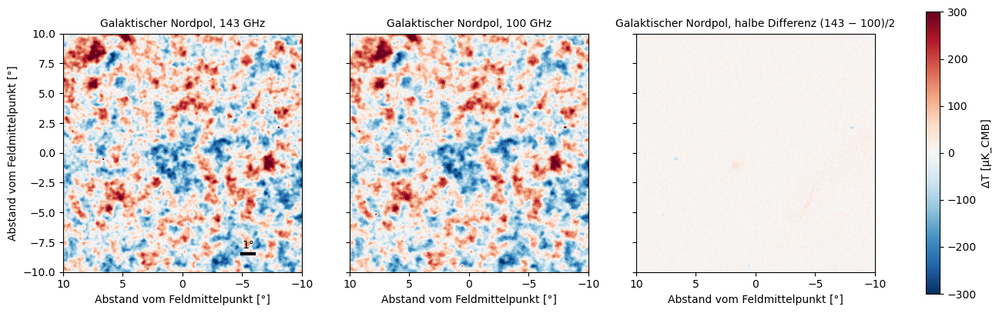

Nordpol        : Streuung 143 GHz 101.8 μK, 100 GHz 101.0 μK, halbe Differenz 11.2 μK, Korrelation 0.9756
Südpol         : Streuung 143 GHz 101.6 μK, 100 GHz 100.8 μK, halbe Differenz 11.1 μK, Korrelation 0.9761
Nord, l = 150° : Streuung 143 GHz  97.6 μK, 100 GHz  96.3 μK, halbe Differenz  9.8 μK, Korrelation 0.9797
Süd, l = 210°  : Streuung 143 GHz 112.9 μK, 100 GHz 112.9 μK, halbe Differenz 12.7 μK, Korrelation 0.9745


In [71]:
cmbpeaks.sky_patch()

**66. Cosmology: Punktquellen**

Radiogalaxien erscheinen als helle Punkte und erhöhen die Leistung bei großem Multipol ℓ (ℓ ≈ 180° / Winkel, großes ℓ heißt kleine Flecken). Ein angepasster Filter sucht sie, und sie werden maskiert.

In den vier Feldern findet der Filter neun Quellen mit 290 bis 880 μK. Ohne sie fällt der Überschuss bei ℓ = 1900 von 2.00 auf 1.55: Die hellsten Quellen machen etwa 40 % aus. Den Rest erklären vermutlich schwächere Quellen unter der Schwelle und der infrarote Hintergrund staubiger Galaxien.

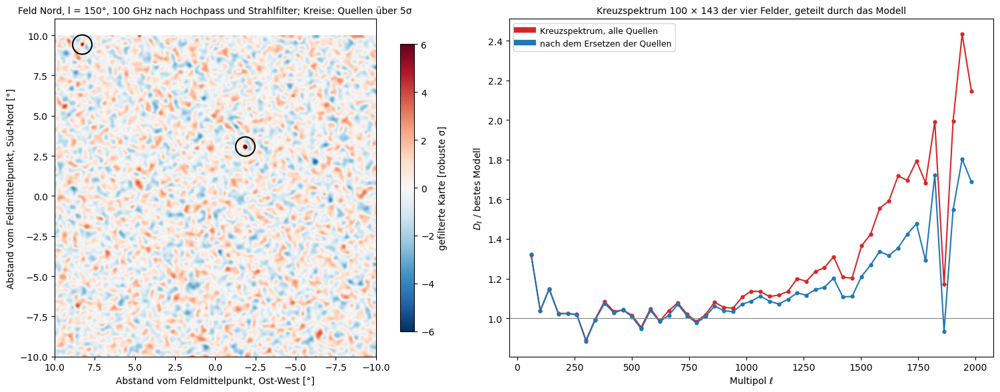

Nordpol        : 3 Quellen; Spitzen bei 100 / 143 GHz [μK]: 571/452, 584/477, 331/317
Südpol         : 3 Quellen; Spitzen bei 100 / 143 GHz [μK]: 468/413, 362/287, 481/543
Nord, l = 150° : 2 Quellen; Spitzen bei 100 / 143 GHz [μK]: 884/777, 333/312
Süd, l = 210°  : 1 Quellen; Spitzen bei 100 / 143 GHz [μK]: 412/444
ℓ ≈  501: Kreuzspektrum / Modell 1.02 mit Quellen, 1.01 ohne
ℓ ≈  982: Kreuzspektrum / Modell 1.11 mit Quellen, 1.07 ohne
ℓ ≈ 1502: Kreuzspektrum / Modell 1.36 mit Quellen, 1.21 ohne
ℓ ≈ 1902: Kreuzspektrum / Modell 2.00 mit Quellen, 1.55 ohne


In [72]:
cmbpeaks.point_sources()